# CitizenTech · Visão Computacional para Manutenção Urbana
## Triagem automática de fissuras em superfícies de concreto

**Objetivo.** Sinalizar automaticamente imagens de fachadas, muros, pontes e calçadas que **merecem inspeção**,
mostrando onde está o possível dano e a confiança do modelo, para que a prefeitura priorize vistorias.

**Tarefa escolhida:** classificação binária (com / sem fissura) com **transferência de aprendizado**,
estendida para *localização aproximada* por janelas deslizantes + Grad-CAM e para **monitoramento em vídeo**.

**Base:** *Concrete Crack Images for Classification* (Özgenel, 2018, Mendeley Data, DOI 10.17632/5y9wdsg2zt.2):
40 000 recortes RGB 227×227 (20 000 com fissura, 20 000 sem), extraídos de 458 fotos de 4032×3024 de prédios do campus METU.

> ⚠️ **Limite de uso.** O sistema faz **triagem**: indica *onde olhar*. A presença de fissura numa imagem,
> isoladamente, **não** determina gravidade nem segurança estrutural — isso exige vistoria de profissional habilitado.

Roteiro: 1) dados → 2) split sem vazamento → 3) pré-processamento → 4) treino de 3 arquiteturas →
5) calibração e limiar → 6) métricas → 7) análise de erros e robustez → 8) localização → 9) vídeo → 10) desempenho.

### ▶️ Rodando no Google Colab
Use **Ambiente de execução → Alterar o tipo → GPU (T4)**. A célula abaixo só age no Colab: recria o pacote
`citizentech_vc` (código embutido neste notebook), baixa a base do Mendeley (~240 MB) e a extrai em `/content`.
Localmente ela não faz nada e o notebook usa a pasta `src/` do projeto.

In [ ]:
import sys, os, json, subprocess, shutil, urllib.request
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    PROJ = Path('/content/citizentech'); PKG = PROJ / 'src' / 'citizentech_vc'
    PKG.mkdir(parents=True, exist_ok=True)
    SRC = json.loads(r'''{"__init__.py": "\"\"\"CitizenTech - módulo de visão computacional para triagem de fissuras em concreto.\"\"\"\n\nCLASSES = [\"sem_fissura\", \"com_fissura\"]\nIMAGENET_MEAN = (0.485, 0.456, 0.406)\nIMAGENET_STD = (0.229, 0.224, 0.225)\n", "bench.py": "\"\"\"Medição de latência e FPS.\"\"\"\nfrom __future__ import annotations\n\nimport platform\nimport time\n\nimport numpy as np\nimport torch\n\nfrom .model import build_model\n\n\ndef hardware_info() -> dict:\n    import psutil\n\n    info = {\n        \"cpu\": platform.processor() or platform.machine(),\n        \"ram_gb\": round(psutil.virtual_memory().total / 2**30, 1),\n        \"so\": f\"{platform.system()} {platform.release()}\",\n        \"python\": platform.python_version(),\n        \"torch\": torch.__version__,\n    }\n    if torch.cuda.is_available():\n        p = torch.cuda.get_device_properties(0)\n        info[\"gpu\"] = p.name\n        info[\"vram_gb\"] = round(p.total_memory / 2**30, 1)\n    return info\n\n\n@torch.no_grad()\ndef bench_model(arch: str, device: str, res: int = 224, batch: int = 1, half: bool = False,\n                n_iter: int = 100, warmup: int = 15, model=None, threads: int | None = None) -> dict:\n    \"\"\"Latência só do modelo (tensor já pronto), média e p95 por lote e por imagem.\"\"\"\n    if threads:\n        torch.set_num_threads(threads)\n    import copy\n\n    m = (copy.deepcopy(model) if model is not None else build_model(arch, pretrained=False)).float().to(device).eval()\n    if half:\n        m = m.half()\n    x = torch.randn(batch, 3, res, res, device=device)\n    if half:\n        x = x.half()\n    valid = bool(torch.isfinite(m(x)).all().item())\n    times = []\n    for i in range(warmup + n_iter):\n        if device == \"cuda\":\n            torch.cuda.synchronize()\n        t0 = time.perf_counter()\n        m(x)\n        if device == \"cuda\":\n            torch.cuda.synchronize()\n        if i >= warmup:\n            times.append(time.perf_counter() - t0)\n    t = np.array(times) * 1000\n    return {\n        \"arquitetura\": arch,\n        \"dispositivo\": device,\n        \"precisao\": \"fp16\" if half else \"fp32\",\n        \"resolucao\": res,\n        \"lote\": batch,\n        \"lat_lote_ms\": float(t.mean()),\n        \"lat_p95_ms\": float(np.percentile(t, 95)),\n        \"lat_img_ms\": float(t.mean() / batch),\n        \"imgs_por_s\": float(1000 * batch / t.mean()),\n        \"saida_valida\": valid,\n    }\n", "config.py": "\"\"\"Configuração única do experimento (usada pelo notebook e por tools/train.py).\"\"\"\n\nSEED = 42\nIMG = 224\nN_PER_CLASS = 6000  # amostra de 12 mil imagens (a base tem 40 mil)\n\n# nome do modelo -> arquitetura + hiperparâmetros\nCONFIGS = {\n    \"mobilenet_v3_large\": dict(arch=\"mobilenet_v3_large\", epochs=5, batch_size=64, lr=1e-3),\n    \"resnet18\": dict(arch=\"resnet18\", epochs=5, batch_size=64, lr=5e-4),\n    \"resnet50\": dict(arch=\"resnet50\", epochs=3, batch_size=32, lr=3e-4),\n    # Melhoria pós-análise de robustez: mesma ResNet18 + aumento de condições de campo\n    \"resnet18_campo\": dict(arch=\"resnet18\", epochs=6, batch_size=64, lr=5e-4, field_aug=True),\n}\n", "data.py": "\"\"\"Preparação dos dados: amostragem, grupos por imagem de origem, split e cache.\n\nA base \"Concrete Crack Images for Classification\" (Özgenel, 2018) tem 40 mil\nrecortes 227x227 gerados a partir de 458 fotos de alta resolução. Os arquivos\nnão informam de qual foto veio cada recorte, então reconstruímos grupos\naproximados para que recortes da mesma foto não fiquem em conjuntos diferentes:\n\n* Positive: os arquivos são numerados na ordem em que foram recortados.\n  Recortes vizinhos na numeração são muito parecidos (ver notebook), então\n  blocos contíguos de numeração formam um grupo.\n* Negative: a numeração foi embaralhada (sem correlação com a vizinhança).\n  Agrupamos por aparência (cor e textura em Lab) com K-Means: recortes da\n  mesma superfície caem no mesmo cluster.\n\nO split treino/validação/teste é feito por grupo, nunca por imagem.\n\"\"\"\nfrom __future__ import annotations\n\nimport hashlib\nimport os\nfrom concurrent.futures import ThreadPoolExecutor\nfrom pathlib import Path\n\nimport cv2\nimport numpy as np\nimport pandas as pd\nfrom sklearn.cluster import KMeans\n\nDEFAULT_ROOT = os.environ.get(\"CRACK_DATA\", r\"C:/Users/lftra/datasets/concrete_crack\")\n\n\ndef file_key(p: Path) -> tuple[int, int]:\n    \"\"\"'10000_1.jpg' -> (1, 10000); '00042.jpg' -> (0, 42).\n\n    A pasta Positive tem duas sequências de recorte: 00001..10621 e 10000_1..19378_1.\n    (Cuidado: int('19378_1') em Python vale 193781, por isso o parse explícito.)\n    \"\"\"\n    base, _, suf = p.stem.partition(\"_\")\n    return (int(suf) if suf else 0, int(base))\n\n\ndef list_images(root: str | Path = DEFAULT_ROOT):\n    root = Path(root)\n    pos = sorted((root / \"Positive\").glob(\"*.jpg\"), key=file_key)\n    neg = sorted((root / \"Negative\").glob(\"*.jpg\"), key=file_key)\n    if not pos or not neg:\n        raise FileNotFoundError(\n            f\"Base não encontrada em {root}. Esperado {root}/Positive e {root}/Negative. \"\n            \"Defina a variável de ambiente CRACK_DATA.\"\n        )\n    return pos, neg\n\n\ndef appearance_features(path: Path, size: int = 64) -> np.ndarray:\n    \"\"\"Média/desvio em Lab + energia de bordas: assinatura barata da superfície.\"\"\"\n    im = cv2.imread(str(path))\n    im = cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)\n    lab = cv2.cvtColor(im, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32)\n    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY).astype(np.float32)\n    lap = cv2.Laplacian(gray, cv2.CV_32F)\n    return np.r_[lab.mean(0), lab.std(0), np.abs(lap).mean(), lap.std()]\n\n\ndef neighbour_distance_profile(paths, gaps=(1, 2, 5, 10, 50, 200, 1000)):\n    \"\"\"Distância média de aparência entre arquivos separados por `gap` na numeração.\"\"\"\n    with ThreadPoolExecutor(8) as ex:\n        f = np.array(list(ex.map(appearance_features, paths)))\n    f = (f - f.mean(0)) / (f.std(0) + 1e-6)\n    return {g: float(np.linalg.norm(f[g:] - f[:-g], axis=1).mean()) for g in gaps if g < len(f)}\n\n\ndef build_sample(\n    root: str | Path = DEFAULT_ROOT,\n    n_per_class: int = 6000,\n    pos_block: int = 100,\n    neg_clusters: int = 150,\n    seed: int = 42,\n) -> pd.DataFrame:\n    \"\"\"Amostra balanceada com coluna `group` (imagem de origem aproximada).\"\"\"\n    rng = np.random.default_rng(seed)\n    pos, neg = list_images(root)\n\n    # Positivos: blocos contíguos inteiros (não quebra grupos ao amostrar)\n    keys = [file_key(p) for p in pos]\n    blocks = [f\"P{s}-{(n - 1) // pos_block:03d}\" for s, n in keys]\n    ub = np.array(sorted(set(blocks)))\n    rng.shuffle(ub)\n    sizes = pd.Series(blocks).value_counts()\n    chosen, acc = set(), 0\n    for b in ub:  # blocos inteiros até atingir n_per_class\n        if acc >= n_per_class:\n            break\n        chosen.add(b)\n        acc += sizes[b]\n    pos_rows = [(str(p), 1, b) for p, b in zip(pos, blocks) if b in chosen]\n\n    # Negativos: amostra aleatória + clusters de aparência como grupos\n    neg_sel = [neg[i] for i in rng.choice(len(neg), size=n_per_class, replace=False)]\n    with ThreadPoolExecutor(8) as ex:\n        feats = np.array(list(ex.map(appearance_features, neg_sel)))\n    feats = (feats - feats.mean(0)) / (feats.std(0) + 1e-6)\n    km = KMeans(n_clusters=neg_clusters, n_init=4, random_state=seed).fit(feats)\n    neg_rows = [(str(p), 0, f\"N{c:04d}\") for p, c in zip(neg_sel, km.labels_)]\n\n    df = pd.DataFrame(pos_rows + neg_rows, columns=[\"path\", \"label\", \"group\"])\n    return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)\n\n\ndef split_by_group(df: pd.DataFrame, fracs=(0.70, 0.15, 0.15), seed: int = 42) -> pd.DataFrame:\n    \"\"\"Atribui train/val/test por grupo, estratificado por classe.\"\"\"\n    rng = np.random.default_rng(seed)\n    df = df.copy()\n    df[\"split\"] = \"\"\n    names = [\"train\", \"val\", \"test\"]\n    for label in sorted(df.label.unique()):\n        sizes = df[df.label == label].groupby(\"group\").size()\n        groups = sizes.index.to_numpy().copy()\n        rng.shuffle(groups)\n        total = sizes.sum()\n        cuts = np.cumsum(fracs)[:-1] * total\n        acc, assign = 0, {}\n        for g in groups:\n            k = int(np.searchsorted(cuts, acc, side=\"right\"))\n            assign[g] = names[k]\n            acc += sizes[g]\n        mask = df.label == label\n        df.loc[mask, \"split\"] = df.loc[mask, \"group\"].map(assign)\n    # Garantia: nenhum grupo em mais de um conjunto\n    assert (df.groupby(\"group\").split.nunique() == 1).all()\n    return df\n\n\ndef _load_rgb(path: str, size: int) -> np.ndarray:\n    im = cv2.imread(path)\n    im = cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)\n    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)\n\n\ndef load_images(paths, size: int = 224, cache_dir: str | Path | None = None) -> np.ndarray:\n    \"\"\"Carrega imagens RGB uint8 (N, size, size, 3), com cache .npy opcional.\"\"\"\n    paths = list(map(str, paths))\n    cache_file = None\n    if cache_dir:\n        key = hashlib.md5((\"|\".join(paths) + str(size)).encode()).hexdigest()[:12]\n        cache_file = Path(cache_dir) / f\"cache_{size}_{key}.npy\"\n        if cache_file.exists():\n            return np.load(cache_file)\n    with ThreadPoolExecutor(8) as ex:\n        arr = np.stack(list(ex.map(lambda p: _load_rgb(p, size), paths)))\n    if cache_file:\n        cache_file.parent.mkdir(parents=True, exist_ok=True)\n        np.save(cache_file, arr)\n    return arr\n", "infer.py": "\"\"\"Inferência para o CitizenTech: recorte único, imagem grande (janelas), Grad-CAM e qualidade.\"\"\"\nfrom __future__ import annotations\n\nimport json\nimport time\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\n\nimport cv2\nimport numpy as np\nimport torch\n\nfrom .model import build_model, gradcam_layer, to_tensor_batch\n\nMODELS_DIR = Path(__file__).resolve().parents[2] / \"models\"\n\n\n@dataclass\nclass TileResult:\n    x: int\n    y: int\n    w: int\n    h: int\n    prob: float\n\n\n@dataclass\nclass ImageAnalysis:\n    prob_max: float\n    frac_tiles: float\n    n_tiles: int\n    tiles: list[TileResult] = field(default_factory=list)\n    latency_ms: float = 0.0\n    tile_size: int = 0\n\n    def decision(self, threshold: float) -> str:\n        return \"INSPEÇÃO RECOMENDADA\" if self.prob_max >= threshold else \"Sem indício de fissura\"\n\n\nclass CrackDetector:\n    \"\"\"Carrega o modelo exportado pelo notebook (models/<arch>.pt + .json).\"\"\"\n\n    def __init__(self, arch: str | None = None, models_dir: str | Path = MODELS_DIR, device: str | None = None, half: bool = False):\n        models_dir = Path(models_dir)\n        if arch is None:\n            arch = json.loads((models_dir / \"selected.json\").read_text(encoding=\"utf-8\"))[\"arch\"]\n        self.cfg = json.loads((models_dir / f\"{arch}.json\").read_text(encoding=\"utf-8\"))\n        self.name = arch\n        self.arch = self.cfg.get(\"arch\", arch)\n        self.device = device or (\"cuda\" if torch.cuda.is_available() else \"cpu\")\n        self.half = half and self.device == \"cuda\"\n        self.size = int(self.cfg.get(\"img_size\", 224))\n        self.temperature = float(self.cfg.get(\"temperature\", 1.0))\n        self.thresholds = self.cfg.get(\"thresholds\", {\"triagem\": 0.5})\n        m = build_model(self.arch, pretrained=False)\n        m.load_state_dict(torch.load(models_dir / f\"{arch}.pt\", map_location=\"cpu\", weights_only=True))\n        self.model = m.to(self.device).eval()\n        if self.half:\n            self.model.half()\n\n    # ------------------------------------------------------------ básico\n    def _prep(self, crops_rgb: list[np.ndarray]) -> torch.Tensor:\n        arr = np.stack([cv2.resize(c, (self.size, self.size), interpolation=cv2.INTER_AREA) for c in crops_rgb])\n        t = to_tensor_batch(arr, self.device)\n        return t.half() if self.half else t\n\n    @torch.no_grad()\n    def predict_crops(self, crops_rgb: list[np.ndarray], batch_size: int = 64) -> np.ndarray:\n        out = []\n        for i in range(0, len(crops_rgb), batch_size):\n            logits = self.model(self._prep(crops_rgb[i : i + batch_size])).float()\n            out.append(torch.softmax(logits / self.temperature, 1)[:, 1].cpu().numpy())\n        return np.concatenate(out) if out else np.zeros(0)\n\n    # ------------------------------------------------------- imagem grande\n    @staticmethod\n    def auto_tile(h: int, w: int) -> int:\n        \"\"\"Recortes da base cobrem ~1/13 da menor dimensão da foto original.\"\"\"\n        if min(h, w) <= 320:\n            return min(h, w)\n        return int(np.clip(min(h, w) / 6, 160, 480))\n\n    def analyze(self, img_rgb: np.ndarray, tile: int | None = None, overlap: float = 0.25) -> ImageAnalysis:\n        t0 = time.perf_counter()\n        h, w = img_rgb.shape[:2]\n        tile = tile or self.auto_tile(h, w)\n        tile = min(tile, h, w)\n        stride = max(1, int(tile * (1 - overlap)))\n        ys = list(range(0, max(h - tile, 0) + 1, stride))\n        xs = list(range(0, max(w - tile, 0) + 1, stride))\n        if ys[-1] + tile < h:\n            ys.append(h - tile)\n        if xs[-1] + tile < w:\n            xs.append(w - tile)\n        coords = [(x, y) for y in ys for x in xs]\n        crops = [img_rgb[y : y + tile, x : x + tile] for x, y in coords]\n        probs = self.predict_crops(crops)\n        if self.device == \"cuda\":\n            torch.cuda.synchronize()\n        tiles = [TileResult(x, y, tile, tile, float(p)) for (x, y), p in zip(coords, probs)]\n        thr = self.thresholds.get(\"triagem\", 0.5)\n        return ImageAnalysis(\n            prob_max=float(probs.max()),\n            frac_tiles=float((probs >= thr).mean()),\n            n_tiles=len(tiles),\n            tiles=tiles,\n            latency_ms=(time.perf_counter() - t0) * 1000,\n            tile_size=tile,\n        )\n\n    # ----------------------------------------------------------- Grad-CAM\n    def gradcam(self, crop_rgb: np.ndarray) -> np.ndarray:\n        \"\"\"Mapa de calor (H,W) em [0,1] das regiões que levaram à classe fissura.\"\"\"\n        model = self.model.float()\n        layer = gradcam_layer(model, self.arch)\n        store = {}\n        h1 = layer.register_forward_hook(lambda m, i, o: store.__setitem__(\"act\", o))\n        try:\n            x = to_tensor_batch(cv2.resize(crop_rgb, (self.size, self.size))[None], self.device)\n            x.requires_grad_(True)\n            with torch.enable_grad():\n                logits = model(x)\n                act = store[\"act\"]\n                grad = torch.autograd.grad(logits[0, 1], act)[0]\n            weights = grad.mean(dim=(2, 3), keepdim=True)\n            cam = torch.relu((weights * act).sum(1))[0].detach().cpu().numpy()\n        finally:\n            h1.remove()\n            if self.half:\n                self.model.half()\n        cam = cv2.resize(cam, (crop_rgb.shape[1], crop_rgb.shape[0]))\n        return cam / (cam.max() + 1e-8)\n\n\n# ------------------------------------------------------------- qualidade\ndef image_quality(img_rgb: np.ndarray) -> dict:\n    \"\"\"Checagens antes de confiar no modelo (nitidez pelo Laplaciano, exposição).\"\"\"\n    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)\n    g = cv2.resize(gray, (512, int(512 * gray.shape[0] / gray.shape[1])))\n    sharp = float(cv2.Laplacian(g, cv2.CV_64F).var())\n    bright = float(g.mean())\n    contrast = float(g.std())\n    alerts = []\n    if sharp < 60:\n        alerts.append(\"Imagem possivelmente borrada (variância do Laplaciano baixa)\")\n    if bright < 50:\n        alerts.append(\"Imagem escura: risco de fissuras não detectadas\")\n    if bright > 215:\n        alerts.append(\"Imagem superexposta\")\n    if contrast < 15:\n        alerts.append(\"Baixo contraste\")\n    return {\"nitidez\": sharp, \"brilho\": bright, \"contraste\": contrast, \"alertas\": alerts}\n\n\n# ------------------------------------------------------------ desenho\ndef draw_analysis(img_rgb: np.ndarray, res: ImageAnalysis, threshold: float, heat_alpha: float = 0.35) -> np.ndarray:\n    \"\"\"Sobrepõe mapa de probabilidade + caixas nas janelas acima do limiar.\"\"\"\n    h, w = img_rgb.shape[:2]\n    heat = heatmap_from_tiles(res, img_rgb.shape)\n    color = cv2.applyColorMap((heat * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]\n    mask = (heat >= threshold)[..., None]\n    out = np.where(mask, (img_rgb * (1 - heat_alpha) + color * heat_alpha).astype(np.uint8), img_rgb)\n    lw = max(2, int(min(h, w) / 300))\n    for (x, y, bw, bh), p in damage_regions(heat, threshold):\n        cv2.rectangle(out, (x, y), (x + bw - 1, y + bh - 1), (255, 40, 40), lw)\n        label = f\"fissura {p:.0%}\"\n        fs = 0.45 * lw / 2 + 0.2\n        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, fs, max(1, lw // 2))\n        cv2.rectangle(out, (x, y), (x + tw + 6, y + th + 8), (255, 40, 40), -1)\n        cv2.putText(out, label, (x + 3, y + th + 4), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), max(1, lw // 2), cv2.LINE_AA)\n    return out\n\n\ndef damage_regions(heat: np.ndarray, threshold: float):\n    \"\"\"Regiões contíguas acima do limiar -> caixas (x, y, w, h) + prob. máxima.\"\"\"\n    mask = (heat >= threshold).astype(np.uint8)\n    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)\n    regions = []\n    for i in range(1, n):\n        x, y, bw, bh, _ = stats[i]\n        regions.append(((int(x), int(y), int(bw), int(bh)), float(heat[lab == i].max())))\n    return sorted(regions, key=lambda r: -r[1])\n\n\ndef heatmap_from_tiles(res: ImageAnalysis, shape) -> np.ndarray:\n    h, w = shape[:2]\n    heat = np.zeros((h, w), np.float32)\n    cnt = np.zeros((h, w), np.float32)\n    for t in res.tiles:\n        heat[t.y : t.y + t.h, t.x : t.x + t.w] += t.prob\n        cnt[t.y : t.y + t.h, t.x : t.x + t.w] += 1\n    return heat / np.maximum(cnt, 1)\n\n\ndef overlay_cam(crop_rgb: np.ndarray, cam: np.ndarray, alpha: float = 0.45) -> np.ndarray:\n    color = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]\n    return (crop_rgb * (1 - alpha) + color * alpha).astype(np.uint8)\n", "model.py": "\"\"\"Arquiteturas (transferência de aprendizado), treino e avaliação.\"\"\"\nfrom __future__ import annotations\n\nimport json\nimport time\nfrom pathlib import Path\n\nimport numpy as np\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nimport torchvision.models as tvm\nfrom sklearn import metrics as skm\n\nfrom . import CLASSES, IMAGENET_MEAN, IMAGENET_STD\n\nARCHS = {\n    # nome: (construtor, pesos ImageNet, camada alvo do Grad-CAM)\n    \"mobilenet_v3_large\": (tvm.mobilenet_v3_large, tvm.MobileNet_V3_Large_Weights.IMAGENET1K_V2),\n    \"resnet50\": (tvm.resnet50, tvm.ResNet50_Weights.IMAGENET1K_V2),\n    \"resnet18\": (tvm.resnet18, tvm.ResNet18_Weights.IMAGENET1K_V1),\n    \"efficientnet_b0\": (tvm.efficientnet_b0, tvm.EfficientNet_B0_Weights.IMAGENET1K_V1),\n}\n\n\ndef build_model(arch: str, pretrained: bool = True, n_classes: int = 2) -> nn.Module:\n    ctor, weights = ARCHS[arch]\n    m = ctor(weights=weights if pretrained else None)\n    if arch.startswith(\"mobilenet\"):\n        m.classifier[3] = nn.Linear(m.classifier[3].in_features, n_classes)\n    elif arch.startswith(\"resnet\"):\n        m.fc = nn.Linear(m.fc.in_features, n_classes)\n    elif arch.startswith(\"efficientnet\"):\n        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)\n    return m\n\n\ndef gradcam_layer(model: nn.Module, arch: str) -> nn.Module:\n    if arch.startswith(\"resnet\"):\n        return model.layer4\n    return model.features[-1]\n\n\ndef count_params(model: nn.Module) -> float:\n    return sum(p.numel() for p in model.parameters()) / 1e6\n\n\n# ----------------------------------------------------------------- tensores\ndef to_tensor_batch(x_uint8: np.ndarray | torch.Tensor, device) -> torch.Tensor:\n    \"\"\"(N,H,W,3) uint8 -> (N,3,H,W) float normalizado ImageNet, no device.\"\"\"\n    t = torch.as_tensor(x_uint8).to(device, non_blocking=True)\n    # .contiguous(): sem isso o tensor fica em layout channels-last e, no GTX 1650,\n    # o cuDNN cai num caminho ~12x mais lento.\n    t = t.permute(0, 3, 1, 2).contiguous().float().div_(255.0)\n    mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)\n    std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)\n    return (t - mean) / std\n\n\ndef gpu_augment(x: torch.Tensor) -> torch.Tensor:\n    \"\"\"Aumento de dados em lote, na GPU (x já normalizado, N,3,H,W).\n\n    Fissuras não têm orientação preferencial -> flips e rotações de 90°.\n    Iluminação varia em campo -> brilho/contraste por amostra.\n    \"\"\"\n    n = x.shape[0]\n    dev = x.device\n    flip_h = torch.rand(n, device=dev) < 0.5\n    x = torch.where(flip_h.view(-1, 1, 1, 1), x.flip(3), x)\n    flip_v = torch.rand(n, device=dev) < 0.5\n    x = torch.where(flip_v.view(-1, 1, 1, 1), x.flip(2), x)\n    if torch.rand(1).item() < 0.5:\n        x = x.transpose(2, 3)\n    contrast = torch.empty(n, 1, 1, 1, device=dev).uniform_(0.7, 1.3)\n    bright = torch.empty(n, 1, 1, 1, device=dev).uniform_(-0.4, 0.4)\n    mean = x.mean(dim=(1, 2, 3), keepdim=True)\n    return (x - mean) * contrast + mean + bright\n\n\ndef field_augment(x: torch.Tensor, p: float = 0.5) -> torch.Tensor:\n    \"\"\"Aumento de \"condições de campo\" (melhoria após a análise de robustez), na GPU.\n\n    Recebe/retorna tensor normalizado ImageNet. Em cada amostra sorteia uma condição:\n    pouca luz (ganho+gama), superexposição, sombra de borda suave, ruído gaussiano\n    ou obstáculo opaco (elipse, até ~20% da área). O rótulo não muda: sombra e\n    obstáculo em superfície SEM fissura ensinam o modelo a não confundir borda com fissura.\n    Os parâmetros são sorteados de forma diferente das perturbações fixas de `perturb.py`\n    usadas na avaliação (formas, intensidades e implementação distintas).\n    \"\"\"\n    n, _, h, w = x.shape\n    dev = x.device\n    mean = torch.tensor(IMAGENET_MEAN, device=dev).view(1, 3, 1, 1)\n    std = torch.tensor(IMAGENET_STD, device=dev).view(1, 3, 1, 1)\n    z = (x * std + mean).clamp(0, 1)\n    apply = torch.rand(n, device=dev) < p\n    kind = torch.randint(0, 5, (n,), device=dev)\n    u = lambda lo, hi: torch.empty(n, 1, 1, 1, device=dev).uniform_(lo, hi)  # noqa: E731\n\n    # 0) pouca luz: ganho 0.2-0.7 e gama 1.0-2.2\n    dark = (z ** u(1.0, 2.2)) * u(0.2, 0.7)\n    # 1) superexposição\n    bright = (z * u(1.3, 2.0) + u(0.0, 0.25)).clamp(0, 1)\n    # 2) sombra: semiplano com borda suave em ângulo aleatório\n    yy, xx = torch.meshgrid(torch.linspace(-1, 1, h, device=dev), torch.linspace(-1, 1, w, device=dev), indexing=\"ij\")\n    ang = torch.rand(n, 1, 1, device=dev) * 2 * np.pi\n    off = torch.empty(n, 1, 1, device=dev).uniform_(-0.6, 0.6)\n    soft = torch.empty(n, 1, 1, device=dev).uniform_(0.01, 0.15)\n    side = torch.sigmoid((torch.cos(ang) * xx + torch.sin(ang) * yy - off) / soft).unsqueeze(1)\n    shadow = z * (1 - u(0.3, 0.75) * side)\n    # 3) ruído\n    noisy = (z + torch.randn_like(z) * u(0.03, 0.12)).clamp(0, 1)\n    # 4) obstáculo: elipse opaca de cor escura/neutra\n    cy, cx = torch.empty(n, 1, 1, device=dev).uniform_(-0.7, 0.7), torch.empty(n, 1, 1, device=dev).uniform_(-0.7, 0.7)\n    ry, rx = torch.empty(n, 1, 1, device=dev).uniform_(0.15, 0.45), torch.empty(n, 1, 1, device=dev).uniform_(0.15, 0.45)\n    ell = ((((yy - cy) / ry) ** 2 + ((xx - cx) / rx) ** 2) <= 1).float().unsqueeze(1)\n    color = torch.rand(n, 3, 1, 1, device=dev) * 0.5\n    occl = z * (1 - ell) + color * ell\n\n    out = z\n    for k, alt in enumerate([dark, bright, shadow, noisy, occl]):\n        sel = (apply & (kind == k)).view(-1, 1, 1, 1)\n        out = torch.where(sel, alt, out)\n    return (out - mean) / std\n\n\n# -------------------------------------------------------------------- treino\ndef train_model(\n    arch: str,\n    x_train: np.ndarray,\n    y_train: np.ndarray,\n    x_val: np.ndarray,\n    y_val: np.ndarray,\n    epochs: int = 4,\n    batch_size: int = 64,\n    lr: float = 3e-4,\n    device: str = \"cuda\",\n    seed: int = 42,\n    amp: bool = False,\n    field_aug: bool = False,\n    log=print,\n):\n    \"\"\"Fine-tuning completo. `field_aug=True` adiciona o aumento de condições de campo. `amp=False` por padrão: nas GTX 16xx o fp16 gera NaN\n    (ResNet50) e ainda é mais lento que fp32 (sem Tensor Cores).\"\"\"\n    torch.manual_seed(seed)\n    np.random.seed(seed)\n    amp = amp and device == \"cuda\"\n    model = build_model(arch).to(device)\n    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)\n    steps = epochs * int(np.ceil(len(x_train) / batch_size))\n    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.15)\n    scaler = torch.amp.GradScaler(\"cuda\", enabled=amp)\n    y_train_t = torch.as_tensor(y_train, dtype=torch.long)\n    history, best = [], {\"val_loss\": 1e9}\n    for ep in range(1, epochs + 1):\n        model.train()\n        t0 = time.perf_counter()\n        perm = np.random.permutation(len(x_train))\n        tot_loss, n_seen = 0.0, 0\n        for i in range(0, len(perm), batch_size):\n            idx = perm[i : i + batch_size]\n            xb = to_tensor_batch(x_train[idx], device)\n            if field_aug:\n                xb = field_augment(xb)\n            xb = gpu_augment(xb)\n            yb = y_train_t[idx].to(device)\n            with torch.autocast(device_type=\"cuda\", dtype=torch.float16, enabled=amp):\n                loss = F.cross_entropy(model(xb), yb)\n            if not torch.isfinite(loss):\n                raise FloatingPointError(f\"perda não finita na época {ep}, lote {i // batch_size}\")\n            opt.zero_grad(set_to_none=True)\n            scaler.scale(loss).backward()\n            scaler.step(opt)\n            scaler.update()\n            sched.step()\n            tot_loss += loss.item() * len(idx)\n            n_seen += len(idx)\n        logits_val = predict_logits(model, x_val, device)\n        val_loss = F.cross_entropy(torch.as_tensor(logits_val), torch.as_tensor(y_val, dtype=torch.long)).item()\n        p_val = torch.softmax(torch.as_tensor(logits_val), 1)[:, 1].numpy()\n        val_f1 = skm.f1_score(y_val, p_val >= 0.5)\n        rec = {\n            \"epoch\": ep,\n            \"train_loss\": tot_loss / n_seen,\n            \"val_loss\": val_loss,\n            \"val_f1@0.5\": val_f1,\n            \"val_acc\": skm.accuracy_score(y_val, p_val >= 0.5),\n            \"seconds\": time.perf_counter() - t0,\n        }\n        history.append(rec)\n        log(\n            f\"[{arch}] época {ep}/{epochs}  loss={rec['train_loss']:.4f}  \"\n            f\"val_loss={val_loss:.4f}  val_F1={val_f1:.4f}  ({rec['seconds']:.0f}s)\"\n        )\n        if val_loss < best[\"val_loss\"]:\n            best = {\"val_loss\": val_loss, \"epoch\": ep, \"state\": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}\n    model.load_state_dict(best[\"state\"])\n    return model, history, best[\"epoch\"]\n\n\n@torch.no_grad()\ndef predict_logits(model: nn.Module, x: np.ndarray, device: str = \"cuda\", batch_size: int = 128) -> np.ndarray:\n    model.eval()\n    out = []\n    for i in range(0, len(x), batch_size):\n        xb = to_tensor_batch(x[i : i + batch_size], device)\n        out.append(model(xb).float().cpu())\n    return torch.cat(out).numpy()\n\n\n# ---------------------------------------------------------------- calibração\ndef fit_temperature(logits: np.ndarray, y: np.ndarray) -> float:\n    \"\"\"Temperature scaling (Guo et al., 2017): ajusta T na validação.\"\"\"\n    lg = torch.as_tensor(logits, dtype=torch.float32)\n    yt = torch.as_tensor(y, dtype=torch.long)\n    log_t = torch.zeros(1, requires_grad=True)\n    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)\n\n    def closure():\n        opt.zero_grad()\n        loss = F.cross_entropy(lg / log_t.exp(), yt)\n        loss.backward()\n        return loss\n\n    opt.step(closure)\n    return float(log_t.exp().item())\n\n\ndef probs_from_logits(logits: np.ndarray, temperature: float = 1.0) -> np.ndarray:\n    return torch.softmax(torch.as_tensor(logits) / temperature, 1)[:, 1].numpy()\n\n\ndef expected_calibration_error(p: np.ndarray, y: np.ndarray, n_bins: int = 15) -> float:\n    conf = np.where(p >= 0.5, p, 1 - p)\n    pred = (p >= 0.5).astype(int)\n    bins = np.linspace(0.5, 1.0, n_bins + 1)\n    ece = 0.0\n    for lo, hi in zip(bins[:-1], bins[1:]):\n        m = (conf > lo) & (conf <= hi)\n        if m.any():\n            ece += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())\n    return float(ece)\n\n\n# ------------------------------------------------------------------ limiares\ndef choose_thresholds(p_val: np.ndarray, y_val: np.ndarray, min_recall: float = 0.99) -> dict:\n    \"\"\"Limiar de triagem: maior limiar com recall >= min_recall na validação.\"\"\"\n    prec, rec, thr = skm.precision_recall_curve(y_val, p_val)\n    prec, rec = prec[:-1], rec[:-1]\n    f1 = 2 * prec * rec / (prec + rec + 1e-12)\n    ok = np.where(rec >= min_recall)[0]\n    t_triage = float(thr[ok[-1]]) if len(ok) else 0.5\n    return {\"triagem\": t_triage, \"f1_max\": float(thr[np.argmax(f1)]), \"padrao\": 0.5}\n\n\ndef classification_report(y: np.ndarray, p: np.ndarray, threshold: float) -> dict:\n    pred = (p >= threshold).astype(int)\n    tn, fp, fn, tp = skm.confusion_matrix(y, pred, labels=[0, 1]).ravel()\n    return {\n        \"limiar\": threshold,\n        \"acuracia\": skm.accuracy_score(y, pred),\n        \"precisao\": skm.precision_score(y, pred, zero_division=0),\n        \"recall\": skm.recall_score(y, pred),\n        \"f1\": skm.f1_score(y, pred),\n        \"especificidade\": tn / (tn + fp),\n        \"roc_auc\": skm.roc_auc_score(y, p),\n        \"pr_auc\": skm.average_precision_score(y, p),\n        \"tn\": int(tn), \"fp\": int(fp), \"fn\": int(fn), \"tp\": int(tp),\n    }\n\n\ndef train_or_load(name: str, ckpt_dir: str | Path, x_train, y_train, x_val, y_val, force: bool = False, log=print, arch: str | None = None, **cfg):\n    \"\"\"Treina e salva checkpoint + histórico; se já existir (e não `force`), carrega.\n\n    Permite retomar o notebook sem retreinar quando a máquina está ocupada.\n    \"\"\"\n    arch = arch or name\n    ckpt_dir = Path(ckpt_dir)\n    ckpt_dir.mkdir(parents=True, exist_ok=True)\n    f_w, f_h = ckpt_dir / f\"{name}.pt\", ckpt_dir / f\"{name}_hist.json\"\n    if f_w.exists() and f_h.exists() and not force:\n        info = json.loads(f_h.read_text(encoding=\"utf-8\"))\n        model = build_model(arch, pretrained=False).to(cfg.get(\"device\", \"cuda\"))\n        model.load_state_dict(torch.load(f_w, map_location=\"cpu\", weights_only=True))\n        log(f\"[{name}] checkpoint carregado ({f_w.name}, treinado em {info['seconds'] / 60:.1f} min)\")\n        return model, info[\"history\"], info[\"best_epoch\"], info[\"seconds\"]\n    t0 = time.time()\n    model, hist, best_ep = train_model(arch, x_train, y_train, x_val, y_val, log=log, **cfg)\n    secs = time.time() - t0\n    torch.save(model.state_dict(), f_w)\n    f_h.write_text(json.dumps({\"history\": hist, \"best_epoch\": best_ep, \"seconds\": secs, \"config\": {k: v for k, v in cfg.items() if k != \"device\"}}, indent=1), encoding=\"utf-8\")\n    return model, hist, best_ep, secs\n\n\n# ----------------------------------------------------------------- exportação\ndef save_bundle(model: nn.Module, name: str, out_dir: str | Path, meta: dict, arch: str | None = None) -> Path:\n    out_dir = Path(out_dir)\n    out_dir.mkdir(parents=True, exist_ok=True)\n    torch.save(model.state_dict(), out_dir / f\"{name}.pt\")\n    cfg = {\"arch\": arch or name, \"name\": name, \"classes\": CLASSES, \"mean\": IMAGENET_MEAN, \"std\": IMAGENET_STD, **meta}\n    (out_dir / f\"{name}.json\").write_text(json.dumps(cfg, indent=2, ensure_ascii=False), encoding=\"utf-8\")\n    return out_dir / f\"{name}.pt\"\n", "perturb.py": "\"\"\"Perturbações de campo para testar robustez (sombra, iluminação, desfoque, ruído, obstáculo).\"\"\"\nfrom __future__ import annotations\n\nimport cv2\nimport numpy as np\n\n\ndef shadow(img: np.ndarray, rng: np.random.Generator, strength: float = 0.55) -> np.ndarray:\n    \"\"\"Sombra de borda dura (poste, marquise) cruzando o recorte.\"\"\"\n    h, w = img.shape[:2]\n    p1 = (int(rng.integers(0, w)), 0)\n    p2 = (int(rng.integers(0, w)), h)\n    side = rng.integers(0, 2)\n    pts = np.array([p1, p2, (w if side else 0, h), (w if side else 0, 0)], np.int32)\n    mask = np.zeros((h, w), np.float32)\n    cv2.fillPoly(mask, [pts], 1.0)\n    mask = cv2.GaussianBlur(mask, (0, 0), 3)[..., None]\n    return np.clip(img * (1 - strength * mask), 0, 255).astype(np.uint8)\n\n\ndef dark(img, rng, factor: float = 0.35):\n    return np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)\n\n\ndef overexposed(img, rng, gain: float = 1.8, offset: float = 40):\n    return np.clip(img.astype(np.float32) * gain + offset, 0, 255).astype(np.uint8)\n\n\ndef blur(img, rng, k: int = 9):\n    return cv2.GaussianBlur(img, (k, k), 0)\n\n\ndef motion_blur(img, rng, k: int = 15):\n    kern = np.zeros((k, k), np.float32)\n    kern[k // 2, :] = 1.0 / k\n    m = cv2.getRotationMatrix2D((k / 2, k / 2), float(rng.uniform(0, 180)), 1)\n    kern = cv2.warpAffine(kern, m, (k, k))\n    kern /= kern.sum()\n    return cv2.filter2D(img, -1, kern)\n\n\ndef noise(img, rng, sigma: float = 25):\n    return np.clip(img + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)\n\n\ndef jpeg(img, rng, quality: int = 15):\n    ok, buf = cv2.imencode(\".jpg\", img[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, quality])\n    return cv2.imdecode(buf, cv2.IMREAD_COLOR)[..., ::-1]\n\n\ndef occlusion(img, rng, frac: float = 0.35):\n    \"\"\"Obstáculo opaco (folha, poste, lixo) cobrindo parte do recorte.\"\"\"\n    out = img.copy()\n    h, w = img.shape[:2]\n    oh, ow = int(h * np.sqrt(frac)), int(w * np.sqrt(frac))\n    y, x = int(rng.integers(0, h - oh)), int(rng.integers(0, w - ow))\n    color = rng.integers(20, 90, 3)\n    out[y : y + oh, x : x + ow] = color\n    return out\n\n\ndef low_res(img, rng, factor: int = 4):\n    h, w = img.shape[:2]\n    small = cv2.resize(img, (w // factor, h // factor), interpolation=cv2.INTER_AREA)\n    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)\n\n\nPERTURBATIONS = {\n    \"original\": lambda img, rng: img,\n    \"sombra\": shadow,\n    \"escura\": dark,\n    \"superexposta\": overexposed,\n    \"desfoque\": blur,\n    \"borrão de movimento\": motion_blur,\n    \"ruído\": noise,\n    \"JPEG forte\": jpeg,\n    \"obstáculo\": occlusion,\n    \"baixa resolução\": low_res,\n}\n\n\ndef apply_all(x: np.ndarray, name: str, seed: int = 0) -> np.ndarray:\n    rng = np.random.default_rng(seed)\n    fn = PERTURBATIONS[name]\n    return np.stack([fn(im, rng) for im in x])\n", "video.py": "\"\"\"Monitoramento contínuo: processamento de vídeo/sequência e geração do vídeo de simulação.\"\"\"\nfrom __future__ import annotations\n\nimport time\nfrom dataclasses import dataclass\nfrom pathlib import Path\n\nimport cv2\nimport numpy as np\n\nfrom .infer import CrackDetector, draw_analysis\n\n\n@dataclass\nclass FrameRecord:\n    frame: int\n    t_video: float\n    prob_max: float\n    frac_tiles: float\n    score_ema: float\n    alerta: bool\n    latency_ms: float\n    fps: float\n\n\ndef build_mosaic(paths_pos, paths_neg, rows: int = 6, cols: int = 16, tile: int = 227, crack_frac: float = 0.22, seed: int = 0):\n    \"\"\"Monta uma 'fachada' com recortes de TESTE (não vistos no treino).\n\n    As fissuras aparecem em trechos contíguos (como numa parede real), não espalhadas.\n    Retorna a imagem RGB e a máscara verdade (rows, cols) com 1 = fissura.\n    \"\"\"\n    rng = np.random.default_rng(seed)\n    truth = np.zeros((rows, cols), np.uint8)\n    n_target = int(rows * cols * crack_frac)\n    while truth.sum() < n_target:  # passeio aleatório -> trechos fissurados contínuos\n        r, c = rng.integers(0, rows), rng.integers(0, cols)\n        for _ in range(rng.integers(3, 8)):\n            truth[r, c] = 1\n            r = int(np.clip(r + rng.integers(-1, 2), 0, rows - 1))\n            c = int(np.clip(c + rng.integers(-1, 2), 0, cols - 1))\n    pos = list(rng.permutation(paths_pos))\n    neg = list(rng.permutation(paths_neg))\n    mosaic = np.zeros((rows * tile, cols * tile, 3), np.uint8)\n    for r in range(rows):\n        for c in range(cols):\n            p = pos.pop() if truth[r, c] else neg.pop()\n            im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)\n            mosaic[r * tile : (r + 1) * tile, c * tile : (c + 1) * tile] = cv2.resize(im, (tile, tile))\n    return mosaic, truth\n\n\ndef pan_frames(mosaic: np.ndarray, out_w: int = 1024, out_h: int = 576, n_frames: int = 360, field_effects: bool = True, seed: int = 1):\n    \"\"\"Câmera percorrendo a fachada (zigue-zague), com sombra passando, variação de luz e tremor.\"\"\"\n    rng = np.random.default_rng(seed)\n    H, W = mosaic.shape[:2]\n    lanes = max(1, int(np.ceil((H - out_h) / (out_h * 0.8))) + 1)\n    ys = np.linspace(0, H - out_h, lanes).astype(int)\n    per_lane = n_frames // lanes\n    for li, y in enumerate(ys):\n        xs = np.linspace(0, W - out_w, per_lane)\n        if li % 2:\n            xs = xs[::-1]\n        for k, x in enumerate(xs):\n            jx, jy = rng.normal(0, 2, 2) if field_effects else (0, 0)\n            x0 = int(np.clip(x + jx, 0, W - out_w))\n            y0 = int(np.clip(y + jy, 0, H - out_h))\n            f = mosaic[y0 : y0 + out_h, x0 : x0 + out_w].astype(np.float32)\n            if field_effects:\n                t = (li * per_lane + k) / n_frames\n                f *= 0.85 + 0.25 * np.sin(2 * np.pi * t * 1.5)  # nuvens / variação de luz\n                sx = int((t * 3 % 1) * (out_w + 400)) - 200  # sombra de poste passando\n                band = np.ones((out_h, out_w), np.float32)\n                band[:, max(0, sx) : max(0, min(out_w, sx + 90))] = 0.5\n                f *= cv2.GaussianBlur(band, (0, 0), 6)[..., None]\n            yield np.clip(f, 0, 255).astype(np.uint8)\n\n\ndef draw_hud(frame: np.ndarray, rec: FrameRecord, threshold: float, device_name: str) -> np.ndarray:\n    out = frame.copy()\n    h, w = out.shape[:2]\n    cv2.rectangle(out, (0, 0), (w, 34), (20, 24, 32), -1)\n    status = \"ALERTA: INSPECIONAR\" if rec.alerta else \"monitorando\"\n    col = (255, 70, 70) if rec.alerta else (120, 220, 140)\n    cv2.putText(out, \"CitizenTech | Monitoramento de fissuras\", (10, 23), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (240, 240, 240), 1, cv2.LINE_AA)\n    cv2.putText(out, status, (w - 250, 23), cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2, cv2.LINE_AA)\n    info = (\n        f\"frame {rec.frame}  conf.max {rec.prob_max:.2f}  area sinalizada {rec.frac_tiles:.0%}  \"\n        f\"latencia {rec.latency_ms:.0f} ms  {rec.fps:.1f} FPS  limiar {threshold:.2f}  [{device_name}]\"\n    )\n    cv2.rectangle(out, (0, h - 28), (w, h), (20, 24, 32), -1)\n    cv2.putText(out, info, (10, h - 9), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (230, 230, 230), 1, cv2.LINE_AA)\n    return out\n\n\ndef monitor(\n    detector: CrackDetector,\n    frames,\n    threshold: float,\n    tile: int | None = None,\n    every: int = 1,\n    ema_alpha: float = 0.4,\n    on_frames: int = 3,\n    video_fps: float = 24.0,\n):\n    \"\"\"Processa uma sequência de quadros. Gera (quadro anotado, FrameRecord).\n\n    Alerta com histerese: liga após `on_frames` quadros com score >= limiar e\n    desliga quando o score médio móvel cai abaixo de 0,8 x limiar. Isso evita\n    alertas piscando por um único quadro ruim.\n    \"\"\"\n    import torch\n\n    dev = torch.cuda.get_device_name(0) if detector.device == \"cuda\" else \"CPU\"\n    ema, streak, alert = 0.0, 0, False\n    last = None\n    t_prev = time.perf_counter()\n    fps_ema = 0.0\n    for i, frame in enumerate(frames):\n        if i % every == 0 or last is None:\n            res = detector.analyze(frame, tile=tile)\n            last = res\n            ema = ema_alpha * res.prob_max + (1 - ema_alpha) * ema\n            streak = streak + 1 if res.prob_max >= threshold else 0\n            if not alert and streak >= on_frames:\n                alert = True\n            elif alert and ema < 0.8 * threshold:\n                alert = False\n        else:\n            res = last\n        annotated = draw_analysis(frame, res, threshold)\n        now = time.perf_counter()\n        inst = 1.0 / max(now - t_prev, 1e-6)\n        t_prev = now\n        fps_ema = inst if fps_ema == 0 else 0.9 * fps_ema + 0.1 * inst\n        rec = FrameRecord(i, i / video_fps, res.prob_max, res.frac_tiles, ema, alert, res.latency_ms, fps_ema)\n        yield draw_hud(annotated, rec, threshold, dev), rec\n\n\ndef read_video(path: str | Path, max_side: int = 1024, max_frames: int | None = None):\n    cap = cv2.VideoCapture(str(path))\n    fps = cap.get(cv2.CAP_PROP_FPS) or 24.0\n    frames = []\n    while True:\n        ok, f = cap.read()\n        if not ok or (max_frames and len(frames) >= max_frames):\n            break\n        h, w = f.shape[:2]\n        s = min(1.0, max_side / max(h, w))\n        if s < 1:\n            f = cv2.resize(f, (int(w * s) // 2 * 2, int(h * s) // 2 * 2), interpolation=cv2.INTER_AREA)\n        frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))\n    cap.release()\n    return frames, fps\n\n\ndef write_video(frames, path: str | Path, fps: float = 24.0):\n    \"\"\"MP4 H.264 (abre no navegador/Streamlit).\"\"\"\n    import imageio.v2 as imageio\n\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    with imageio.get_writer(path, fps=fps, codec=\"libx264\", quality=7, macro_block_size=8, pixelformat=\"yuv420p\") as wr:\n        for f in frames:\n            wr.append_data(f)\n    return path\n"}''')
    for name, txt in SRC.items():
        (PKG / name).write_text(txt, encoding='utf-8')
    DATA_DIR = Path('/content/concrete_crack')
    if not (DATA_DIR / 'Positive').exists():
        rar = Path('/content/concrete.rar')
        # Alternativa: se você já subiu o .rar para o Google Drive, ele é usado no lugar do download
        drive_rar = [p for p in Path('/content/drive/MyDrive').glob('**/Concrete Crack Images for Classification.rar')] if Path('/content/drive/MyDrive').exists() else []
        if drive_rar:
            shutil.copy(drive_rar[0], rar); print('usando', drive_rar[0])
        elif not rar.exists() or rar.stat().st_size < 241_000_000:
            url = 'https://data.mendeley.com/public-files/datasets/5y9wdsg2zt/files/8a70d8a5-bce9-4291-bab9-b48cfb3e87c3/file_downloaded'
            # O Mendeley responde 403 ao User-Agent padrão do urllib; com um de navegador funciona
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0 Safari/537.36'})
            print('baixando a base (~240 MB)...')
            with urllib.request.urlopen(req, timeout=600) as r, open(rar, 'wb') as fh:
                shutil.copyfileobj(r, fh, 1 << 20)
        if shutil.which('unrar') is None:
            subprocess.run(['apt-get', 'install', '-y', '-qq', 'unrar'], check=True)
        DATA_DIR.mkdir(exist_ok=True)
        subprocess.run(['unrar', 'x', '-o+', '-inul', '/content/concrete.rar', str(DATA_DIR) + '/'], check=True)
        rar.unlink(missing_ok=True)
    try:
        import imageio_ffmpeg  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imageio-ffmpeg'], check=True)
    os.environ['CRACK_DATA'] = str(DATA_DIR)
    os.chdir(PROJ)
    print('Colab pronto:', PROJ, '| imagens:', len(list((DATA_DIR / 'Positive').glob('*.jpg'))), '+', len(list((DATA_DIR / 'Negative').glob('*.jpg'))))
else:
    print('Execução local: usando src/ do projeto')

In [2]:
import os, sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
from sklearn import metrics as skm
from citizentech_vc import CLASSES, data, model as M, perturb, video, bench
from citizentech_vc.infer import CrackDetector, draw_analysis, overlay_cam, image_quality

DATA = Path(os.environ.get("CRACK_DATA", data.DEFAULT_ROOT))
CACHE = DATA.parent / "cache_citizentech"
FIGS = ROOT / "reports" / "figs"; FIGS.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
DEMO = ROOT / "demo"; DEMO.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
from citizentech_vc.config import SEED, IMG, N_PER_CLASS
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 9})
torch.backends.cudnn.benchmark = True

HW = bench.hardware_info()
print(json.dumps(HW, indent=1, ensure_ascii=False)); print("dispositivo:", DEVICE, "| base:", DATA)
RESULTS = {"hardware": HW}
def savefig(name):
    plt.savefig(FIGS / f"{name}.png", bbox_inches="tight", dpi=130)

{
 "cpu": "Intel64 Family 6 Model 165 Stepping 2, GenuineIntel",
 "ram_gb": 31.9,
 "so": "Windows 11",
 "python": "3.14.7",
 "torch": "2.11.0+cu128",
 "gpu": "NVIDIA GeForce GTX 1650",
 "vram_gb": 4.0
}
dispositivo: cuda | base: C:\Users\lftra\datasets\concrete_crack


## 1. Exame dos dados

Positive (com fissura): 20000 | Negative (sem fissura): 20000
Tamanhos (amostra): {(227, 227, 3): np.int64(40)}


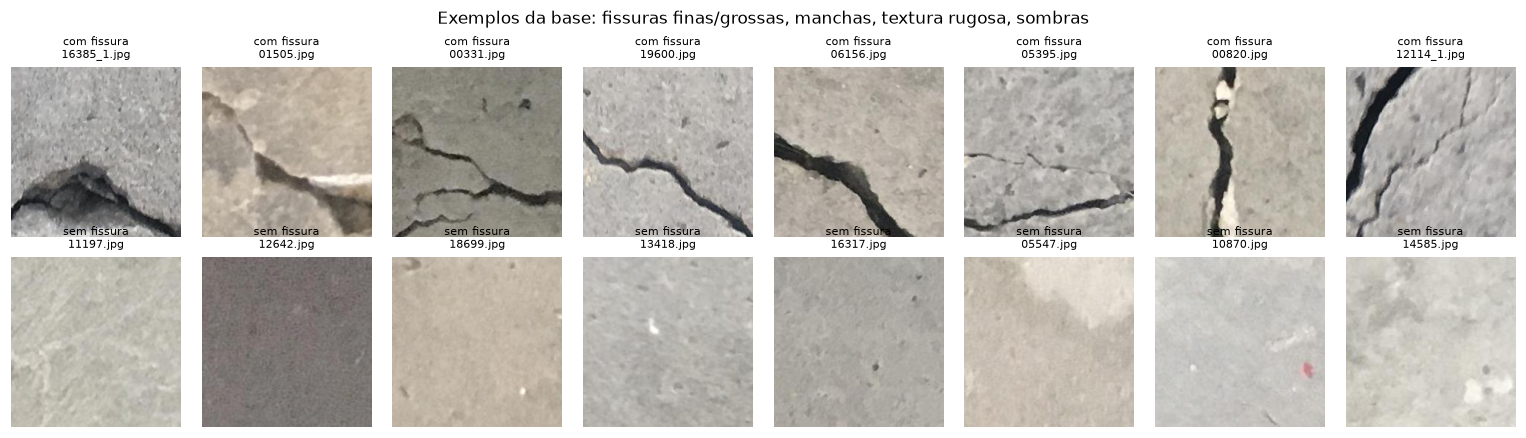

In [3]:
pos, neg = data.list_images(DATA)
print(f"Positive (com fissura): {len(pos)} | Negative (sem fissura): {len(neg)}")
shapes = pd.Series([cv2.imread(str(p)).shape for p in pos[:200:10] + neg[:200:10]]).value_counts()
print("Tamanhos (amostra):", dict(shapes))

rng = np.random.default_rng(0)
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for r, (lst, name) in enumerate([(pos, "com fissura"), (neg, "sem fissura")]):
    for c, i in enumerate(rng.choice(len(lst), 8, replace=False)):
        ax[r, c].imshow(cv2.imread(str(lst[i]))[..., ::-1]); ax[r, c].axis("off")
        ax[r, c].set_title(f"{name}\n{lst[i].name}", fontsize=7)
plt.suptitle("Exemplos da base: fissuras finas/grossas, manchas, textura rugosa, sombras"); plt.tight_layout(); savefig("01_exemplos"); plt.show()

**Por que o split precisa de cuidado.** Os 40 mil recortes vêm de apenas 458 fotos: recortes da mesma foto compartilham
iluminação, cor e textura do concreto. Se recortes de uma mesma foto caem em treino e teste, o modelo "reconhece a parede"
e a métrica fica otimista. A base não informa a foto de origem, então medimos se a **numeração dos arquivos** preserva
a vizinhança: distância de aparência (cor Lab + bordas) entre arquivos separados por *k* posições.

,Positive,Negative
distância na numeração,,
1,1.615,3.652
2,1.884,3.649
5,2.393,3.637
10,2.867,3.631
50,3.451,3.690
200,3.644,3.677
1000,3.903,3.638


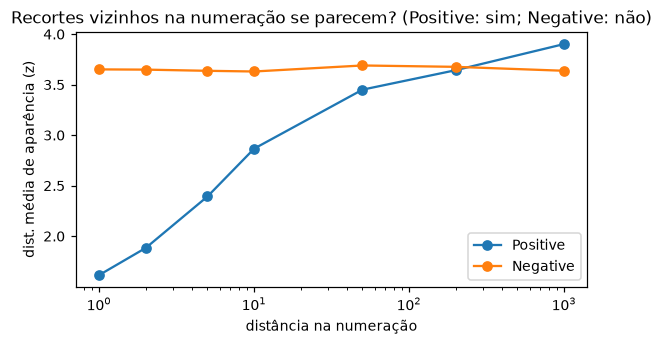

In [4]:
prof_pos = data.neighbour_distance_profile(pos[:3000])
prof_neg = data.neighbour_distance_profile(neg[:3000])
prof = pd.DataFrame({"Positive": prof_pos, "Negative": prof_neg}); prof.index.name = "distância na numeração"
display(prof.round(3))
ax = prof.plot(marker="o", logx=True, figsize=(6, 3)); ax.set_ylabel("dist. média de aparência (z)")
ax.set_title("Recortes vizinhos na numeração se parecem? (Positive: sim; Negative: não)"); savefig("02_vizinhanca"); plt.show()
RESULTS["vizinhanca"] = prof.round(3).to_dict()

**Leitura:** (a pasta *Positive* tem duas sequências de numeração, `00001…10621` e `10000_1…19378_1`; ordenamos por sequência e número.) Nos *Positive* a distância cresce com o salto na numeração → arquivos próximos vêm da mesma foto
(agrupamos em **blocos contíguos de 100**). Nos *Negative* a distância é constante → a numeração foi embaralhada;
agrupamos por **aparência** (K-Means em cor/textura, 150 clusters), de modo que recortes da mesma superfície fiquem juntos.
O split 70/15/15 é feito **por grupo**, estratificado por classe.

## 2. Amostra e split treino / validação / teste sem vazamento

In [5]:
# N_PER_CLASS = 6000 (config.py): amostra de 12 mil imagens para caber no prazo de ~4h; a base completa tem 40 mil
t0 = time.time()
df = data.build_sample(DATA, n_per_class=N_PER_CLASS, seed=SEED)
df = data.split_by_group(df, seed=SEED)
print(f"amostra montada em {time.time()-t0:.0f}s")
tab = pd.crosstab(df.split, df.label.map(dict(enumerate(CLASSES))), margins=True)
display(tab)
print("grupos por conjunto:", df.groupby("split").group.nunique().to_dict())
print("grupos presentes em >1 conjunto:", int((df.groupby("group").split.nunique() > 1).sum()))
df.to_csv(ROOT / "reports" / "split.csv", index=False)
RESULTS["split"] = {s: {"n": int((df.split == s).sum()), "grupos": int(df[df.split == s].group.nunique())} for s in ["train", "val", "test"]}

amostra montada em 8s


label,com_fissura,sem_fissura,All
split,,,
test,878,831,1709
train,4301,4212,8513
val,900,957,1857
All,6079,6000,12079


grupos por conjunto: {'test': 30, 'train': 151, 'val': 31}
grupos presentes em >1 conjunto: 0


**Verificação do vazamento.** Para cada imagem de teste, medimos a distância até a imagem de treino mais parecida.
Num split aleatório (o "errado") o teste tem "gêmeos" no treino; no split por grupo, não.

dist. mediana teste→treino  | split por grupo: 0.537 | split aleatório: 0.429


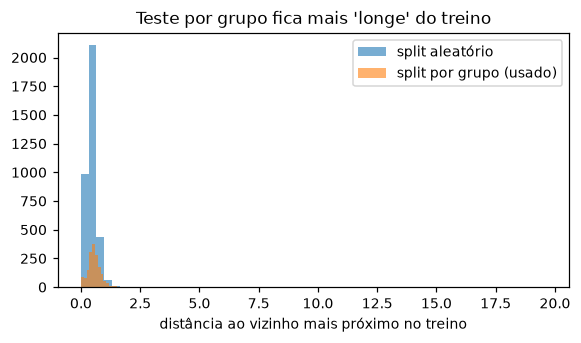

In [6]:
from concurrent.futures import ThreadPoolExecutor
from sklearn.neighbors import NearestNeighbors
with ThreadPoolExecutor(8) as ex:
    F = np.array(list(ex.map(lambda p: data.appearance_features(Path(p)), df.path)))
F = (F - F.mean(0)) / F.std(0)

def nn_dist(train_mask, test_mask):
    nn = NearestNeighbors(n_neighbors=1).fit(F[train_mask]); return nn.kneighbors(F[test_mask])[0][:, 0]
rand = np.random.default_rng(SEED).permutation(len(df)) < 0.7 * len(df)
d_group = nn_dist((df.split == "train").values, (df.split == "test").values)
d_rand = nn_dist(rand, ~rand)
print(f"dist. mediana teste→treino  | split por grupo: {np.median(d_group):.3f} | split aleatório: {np.median(d_rand):.3f}")
plt.figure(figsize=(6, 3)); plt.hist(d_rand, 60, alpha=.6, label="split aleatório"); plt.hist(d_group, 60, alpha=.6, label="split por grupo (usado)")
plt.xlabel("distância ao vizinho mais próximo no treino"); plt.legend(); plt.title("Teste por grupo fica mais 'longe' do treino"); savefig("03_vazamento"); plt.show()
RESULTS["vazamento"] = {"mediana_grupo": float(np.median(d_group)), "mediana_aleatorio": float(np.median(d_rand))}

## 3. Pré-processamento
* **Redimensionamento** 227→224 (INTER_AREA, sem distorção: as imagens já são quadradas) — entrada nativa das redes ImageNet.
* **Normalização** pela média/desvio do ImageNet, porque usamos pesos pré-treinados nele.
* **Aumento de dados** (só treino, na GPU): flips H/V e transposição (fissura não tem orientação), brilho ±0,4 e contraste 0,7–1,3 (iluminação de campo).
* Imagens decodificadas uma vez e guardadas em cache `uint8` (≈1,8 GB em RAM) para o treino não ficar preso em leitura de JPEG.

{'train': (8513, 224, 224, 3), 'val': (1857, 224, 224, 3), 'test': (1709, 224, 224, 3)} | 2s


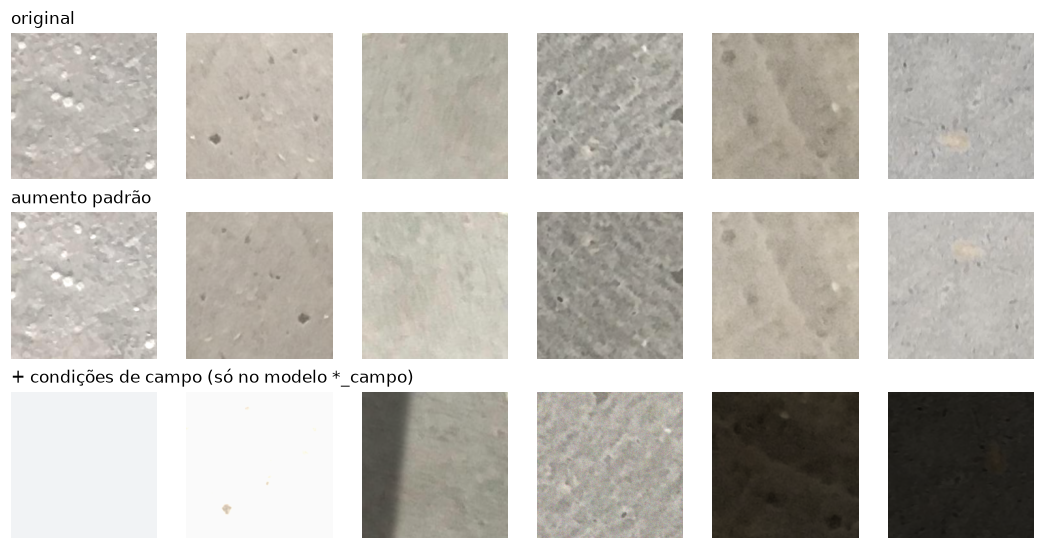

In [7]:
t0 = time.time()
X = {s: data.load_images(df[df.split == s].path, IMG, cache_dir=CACHE) for s in ["train", "val", "test"]}
Y = {s: df[df.split == s].label.to_numpy() for s in ["train", "val", "test"]}
P = {s: df[df.split == s].path.tolist() for s in ["train", "val", "test"]}
print({s: X[s].shape for s in X}, f"| {time.time()-t0:.0f}s")

xb = M.to_tensor_batch(X["train"][:6], DEVICE); xa = M.gpu_augment(xb)
std = torch.tensor(M.IMAGENET_STD, device=DEVICE).view(1,3,1,1); mean = torch.tensor(M.IMAGENET_MEAN, device=DEVICE).view(1,3,1,1)
show = lambda t: (t * std + mean).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
xc = M.gpu_augment(M.field_augment(xb, p=1.0))
fig, ax = plt.subplots(3, 6, figsize=(12, 6))
for i in range(6):
    for r, t in enumerate([xb, xa, xc]): ax[r, i].imshow(show(t)[i]); ax[r, i].axis("off")
ax[0, 0].set_title("original", loc="left"); ax[1, 0].set_title("aumento padrão", loc="left"); ax[2, 0].set_title("+ condições de campo (só no modelo *_campo)", loc="left")
savefig("04_aumento"); plt.show()

## 4. Modelos — transferência de aprendizado
Comparamos três CNNs pré-treinadas no ImageNet, com *fine-tuning* completo (AdamW, OneCycle, fp32).

> **Nota de engenharia (GTX 1650).** Testamos precisão mista fp16: nas GTX 16xx (sem Tensor Cores) ela foi **mais lenta** que fp32 e gerou **NaN** no ResNet50, e o EfficientNet-B0 treinou a apenas ~24 img/s. Por isso treinamos e servimos em fp32 e trocamos o EfficientNet-B0 pelo ResNet18. Também foi preciso tornar o tensor de entrada contíguo após o `permute` (layout channels-last deixava o cuDNN ~12× mais lento).

| Modelo | Por que testar |
|---|---|
| **MobileNetV3-Large** | feita para dispositivos móveis/borda; candidata a tempo real (câmera de viatura, celular do fiscal) |
| **ResNet18** | ResNet rasa: meio-termo entre custo e capacidade |
| **ResNet50** | referência clássica (a mesma usada em aula com Keras), mais pesada |
| **ResNet18 + campo** | *melhoria*: a mesma ResNet18 treinada também com **aumento de condições de campo** (pouca luz, superexposição, sombra, ruído, obstáculo), criada depois de a análise de robustez da 1ª rodada mostrar quedas fortes nessas condições |

A seleção do modelo usa **somente a validação**; o teste é usado uma única vez no final.

In [8]:
from citizentech_vc.config import CONFIGS   # mesma configuração de tools/train.py
FORCE_TRAIN = False   # True = retreina mesmo havendo checkpoint em models/ckpt/ (gerado por tools/train.py ou por este notebook)
print(json.dumps(CONFIGS, indent=1))
models, hist, train_time = {}, {}, {}
for arch, cfg in CONFIGS.items():
    models[arch], hist[arch], best_ep, train_time[arch] = M.train_or_load(
        arch, MODELS / "ckpt", X["train"], Y["train"], X["val"], Y["val"], force=FORCE_TRAIN, device=DEVICE, seed=SEED, **cfg)
    print(f"  -> melhor época {best_ep}, treino em {train_time[arch]/60:.1f} min\n")
    torch.cuda.empty_cache()

{
 "mobilenet_v3_large": {
  "arch": "mobilenet_v3_large",
  "epochs": 5,
  "batch_size": 64,
  "lr": 0.001
 },
 "resnet18": {
  "arch": "resnet18",
  "epochs": 5,
  "batch_size": 64,
  "lr": 0.0005
 },
 "resnet50": {
  "arch": "resnet50",
  "epochs": 3,
  "batch_size": 32,
  "lr": 0.0003
 },
 "resnet18_campo": {
  "arch": "resnet18",
  "epochs": 6,
  "batch_size": 64,
  "lr": 0.0005,
  "field_aug": true
 }
}


[mobilenet_v3_large] checkpoint carregado (mobilenet_v3_large.pt, treinado em 10.4 min)
  -> melhor época 5, treino em 10.4 min



[resnet18] checkpoint carregado (resnet18.pt, treinado em 4.0 min)
  -> melhor época 5, treino em 4.0 min



[resnet50] checkpoint carregado (resnet50.pt, treinado em 21.5 min)
  -> melhor época 2, treino em 21.5 min



[resnet18_campo] checkpoint carregado (resnet18_campo.pt, treinado em 5.1 min)
  -> melhor época 5, treino em 5.1 min



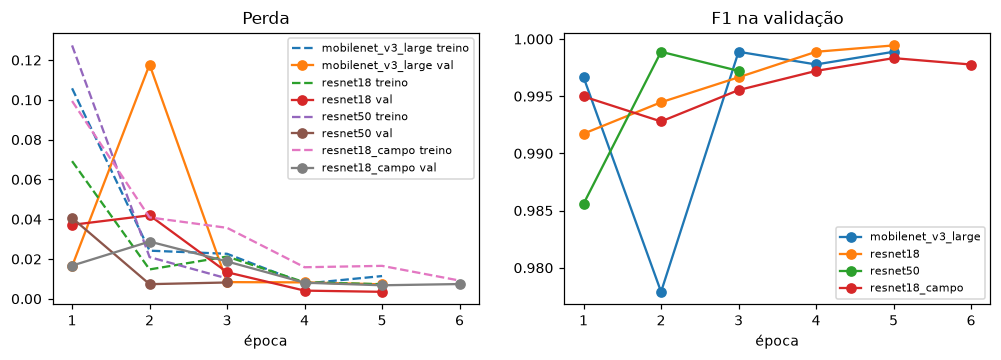

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for arch, h in hist.items():
    h = pd.DataFrame(h)
    ax[0].plot(h.epoch, h.train_loss, "--", label=f"{arch} treino"); ax[0].plot(h.epoch, h.val_loss, "-o", label=f"{arch} val")
    ax[1].plot(h.epoch, h["val_f1@0.5"], "-o", label=arch)
ax[0].set_title("Perda"); ax[0].set_xlabel("época"); ax[0].legend(fontsize=7); ax[1].set_title("F1 na validação"); ax[1].set_xlabel("época"); ax[1].legend(fontsize=7)
savefig("05_curvas"); plt.show()

## 5. Calibração da confiança e escolha do limiar
* **Confiança calibrada.** Redes modernas tendem a ser confiantes demais. Ajustamos uma *temperatura* T na validação
  (temperature scaling): a probabilidade exibida no CitizenTech passa a significar algo próximo de "x% dos casos com essa confiança são fissura". Medimos pelo **ECE** (erro de calibração esperado).
* **Limiar de triagem.** Num serviço de manutenção, **deixar passar uma fissura (FN) custa mais** do que mandar um fiscal
  olhar uma parede sã (FP). Escolhemos na validação o **maior limiar com recall ≥ 99%**; também reportamos o limiar que maximiza F1 e o 0,5.

In [10]:
calib, thr, logits = {}, {}, {}
for arch, m in models.items():
    logits[arch] = {s: M.predict_logits(m, X[s], DEVICE) for s in ["val", "test"]}
    T = M.fit_temperature(logits[arch]["val"], Y["val"])
    p_val_raw = M.probs_from_logits(logits[arch]["val"]); p_val = M.probs_from_logits(logits[arch]["val"], T)
    calib[arch] = {"T": T, "ece_val_antes": M.expected_calibration_error(p_val_raw, Y["val"]), "ece_val_depois": M.expected_calibration_error(p_val, Y["val"])}
    thr[arch] = M.choose_thresholds(p_val, Y["val"], min_recall=0.99)
display(pd.DataFrame(calib).T.round(4)); display(pd.DataFrame(thr).T.round(4))

,T,ece_val_antes,ece_val_depois
mobilenet_v3_large,1.3651,0.0015,0.0015
resnet18,1.0030,0.0013,0.0013
resnet50,1.0436,0.0017,0.0019
resnet18_campo,1.1622,0.0017,0.0016


,triagem,f1_max,padrao
mobilenet_v3_large,0.9534,0.5522,0.5
resnet18,0.9847,0.5584,0.5
resnet50,0.9485,0.5841,0.5
resnet18_campo,0.9445,0.1392,0.5


## 6. Métricas — validação (seleção) e teste (resultado final)

In [11]:
rows = []
for arch in models:
    T = calib[arch]["T"]
    for split in ["val", "test"]:
        p = M.probs_from_logits(logits[arch][split], T)
        for name, t in thr[arch].items():
            r = M.classification_report(Y[split], p, t); r.update(modelo=arch, conjunto=split, criterio=name); rows.append(r)
met = pd.DataFrame(rows)
cols = ["modelo", "conjunto", "criterio", "limiar", "acuracia", "precisao", "recall", "f1", "especificidade", "roc_auc", "pr_auc", "fp", "fn"]
display(met[cols].round(4))
met[cols].to_csv(ROOT / "reports" / "metricas.csv", index=False)

,modelo,conjunto,criterio,limiar,acuracia,precisao,recall,f1,especificidade,roc_auc,pr_auc,fp,fn
0,mobilenet_v3_large,val,triagem,0.9534,0.9946,0.9989,0.9900,0.9944,0.9990,1.0000,1.0000,1,9
1,mobilenet_v3_large,val,f1_max,0.5522,0.9989,0.9989,0.9989,0.9989,0.9990,1.0000,1.0000,1,1
2,mobilenet_v3_large,val,padrao,0.5000,0.9989,0.9989,0.9989,0.9989,0.9990,1.0000,1.0000,1,1
3,mobilenet_v3_large,test,triagem,0.9534,0.9988,1.0000,0.9977,0.9989,1.0000,1.0000,1.0000,0,2
4,mobilenet_v3_large,test,f1_max,0.5522,0.9988,0.9989,0.9989,0.9989,0.9988,1.0000,1.0000,1,1
5,mobilenet_v3_large,test,padrao,0.5000,0.9988,0.9989,0.9989,0.9989,0.9988,1.0000,1.0000,1,1
6,resnet18,val,triagem,0.9847,0.9952,1.0000,0.9900,0.9950,1.0000,1.0000,1.0000,0,9
7,resnet18,val,f1_max,0.5584,0.9995,0.9989,1.0000,0.9994,0.9990,1.0000,1.0000,1,0
8,resnet18,val,padrao,0.5000,0.9995,0.9989,1.0000,0.9994,0.9990,1.0000,1.0000,1,0
9,resnet18,test,triagem,0.9847,0.9977,1.0000,0.9954,0.9977,1.0000,1.0000,1.0000,0,4


In [12]:
# Seleção usando SÓ a validação:
#  1) qualidade em imagem limpa: F1 no limiar de triagem a até 0,5 p.p. do melhor;
#  2) entre esses, maior F1 médio sob as perturbações de campo (aplicadas à VALIDAÇÃO);
#  3) empate (< 0,5 p.p.) -> menor latência.
lat_quick = {a: bench.bench_model(a, DEVICE, batch=1, half=False, n_iter=50, model=models[a])["lat_img_ms"] for a in models}
val_tri = met[(met.conjunto == "val") & (met.criterio == "triagem")].set_index("modelo")
Xval_pert = {name: perturb.apply_all(X["val"], name, seed=SEED + 1) for name in perturb.PERTURBATIONS if name != "original"}
rob_val = {a: np.mean([M.classification_report(Y["val"], M.probs_from_logits(M.predict_logits(models[a], xp, DEVICE), calib[a]["T"]), thr[a]["triagem"])["f1"]
                       for xp in Xval_pert.values()]) for a in models}
del Xval_pert
sel_tab = pd.DataFrame({"F1 val limpa": val_tri.f1, "F1 val médio c/ perturbações": pd.Series(rob_val), "latência lote 1 (ms)": pd.Series(lat_quick)})
display(sel_tab.round(4))
cands = [a for a in models if val_tri.loc[a, "f1"] >= val_tri.f1.max() - 0.005]
best_rob = max(rob_val[a] for a in cands)
cands = [a for a in cands if rob_val[a] >= best_rob - 0.005]
SELECTED = min(cands, key=lambda a: lat_quick[a])
print("==> modelo selecionado:", SELECTED)
RESULTS["selecao"] = sel_tab.round(4).to_dict(orient="index")
for name_, m in models.items():
    M.save_bundle(m, name_, MODELS, {"img_size": IMG, "temperature": calib[name_]["T"], "thresholds": thr[name_], "field_aug": bool(CONFIGS[name_].get("field_aug", False)),
                                     "params_M": round(M.count_params(m), 2), "train_minutes": round(train_time[name_] / 60, 2)}, arch=CONFIGS[name_]["arch"])
(MODELS / "selected.json").write_text(json.dumps({"arch": SELECTED}), encoding="utf-8")
RESULTS["selecionado"] = SELECTED

,F1 val limpa,F1 val médio c/ perturbações,latência lote 1 (ms)
mobilenet_v3_large,0.9944,0.6978,21.4311
resnet18,0.9950,0.8166,8.0072
resnet50,0.9944,0.8793,17.2197
resnet18_campo,0.9944,0.9708,9.3197


==> modelo selecionado: resnet18_campo


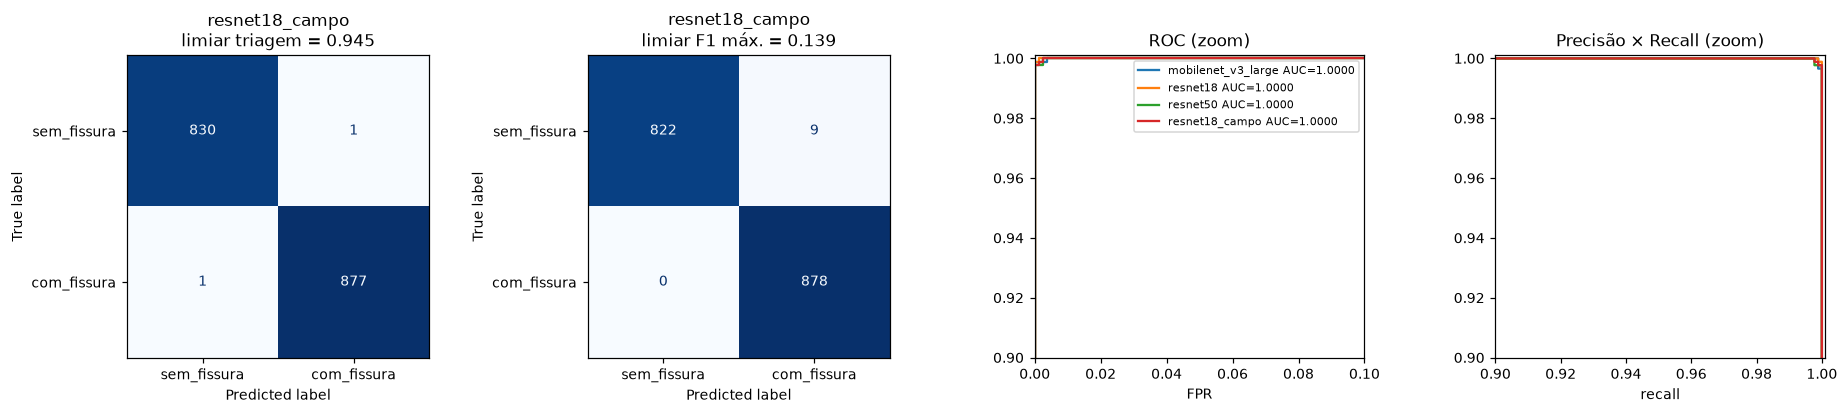

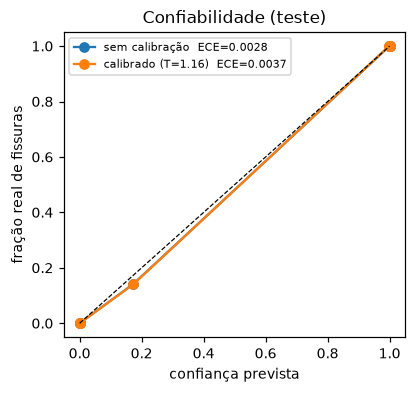

In [13]:
T, t_tri = calib[SELECTED]["T"], thr[SELECTED]["triagem"]
p_test = M.probs_from_logits(logits[SELECTED]["test"], T); y_test = Y["test"]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for i, (name, t) in enumerate([("triagem", t_tri), ("F1 máx.", thr[SELECTED]["f1_max"])]):
    cm = skm.confusion_matrix(y_test, p_test >= t)
    skm.ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[i], colorbar=False, cmap="Blues")
    ax[i].set_title(f"{SELECTED}\nlimiar {name} = {t:.3f}")
for arch in models:
    p = M.probs_from_logits(logits[arch]["test"], calib[arch]["T"])
    fpr, tpr, _ = skm.roc_curve(y_test, p); pr, rc, _ = skm.precision_recall_curve(y_test, p)
    ax[2].plot(fpr, tpr, label=f"{arch} AUC={skm.auc(fpr, tpr):.4f}"); ax[3].plot(rc, pr, label=arch)
ax[2].set_xlim(0, .1); ax[2].set_ylim(.9, 1.001); ax[2].set_title("ROC (zoom)"); ax[2].set_xlabel("FPR"); ax[2].legend(fontsize=7)
ax[3].set_xlim(.9, 1.001); ax[3].set_ylim(.9, 1.001); ax[3].set_title("Precisão × Recall (zoom)"); ax[3].set_xlabel("recall")
plt.tight_layout(); savefig("06_confusao_roc_pr"); plt.show()

# diagrama de confiabilidade
p_raw = M.probs_from_logits(logits[SELECTED]["test"])
fig, ax = plt.subplots(figsize=(4, 3.6))
for pp, lab in [(p_raw, "sem calibração"), (p_test, f"calibrado (T={T:.2f})")]:
    pt, pm = __import__("sklearn.calibration", fromlist=["x"]).calibration_curve(y_test, pp, n_bins=10, strategy="quantile")
    ax.plot(pm, pt, "o-", label=f"{lab}  ECE={M.expected_calibration_error(pp, y_test):.4f}")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("confiança prevista"); ax.set_ylabel("fração real de fissuras"); ax.legend(fontsize=7)
ax.set_title("Confiabilidade (teste)"); savefig("07_calibracao"); plt.show()

## 7. Análise de acertos e erros

FP=1  FN=1  (de 1709 imagens de teste)


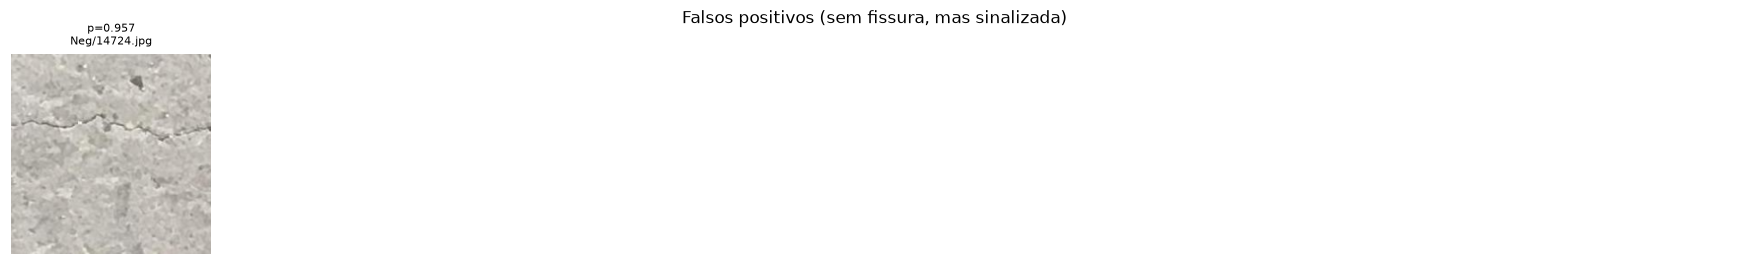

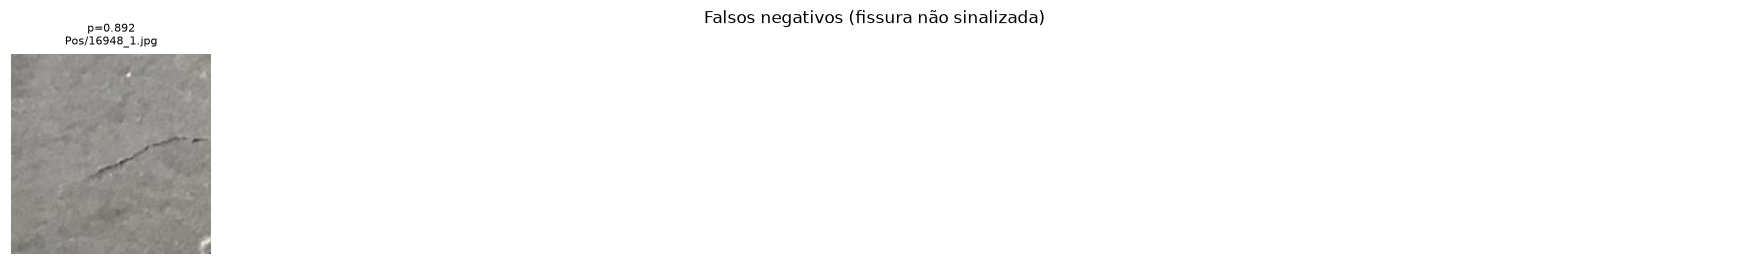

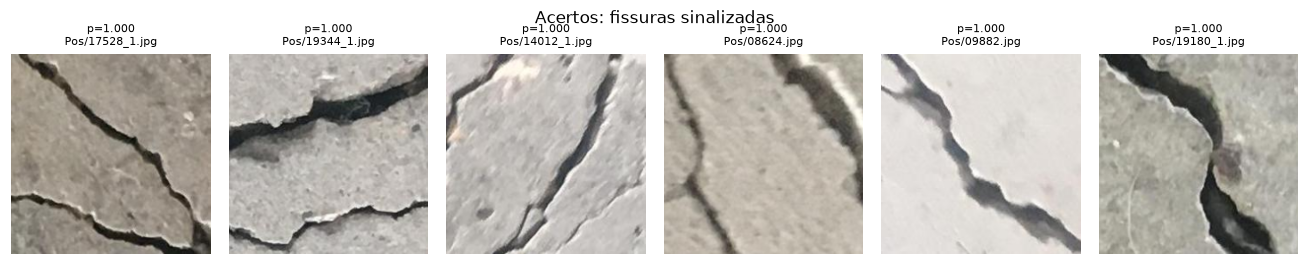

In [14]:
pred = p_test >= t_tri
idx_fp = np.where(pred & (y_test == 0))[0]; idx_fn = np.where(~pred & (y_test == 1))[0]
idx_tp = np.where(pred & (y_test == 1))[0]; idx_tn = np.where(~pred & (y_test == 0))[0]
print(f"FP={len(idx_fp)}  FN={len(idx_fn)}  (de {len(y_test)} imagens de teste)")

def grid(idxs, title, name, n=8):
    idxs = sorted(idxs, key=lambda i: -abs(p_test[i] - t_tri))[:n]
    if not len(idxs): print("nenhum:", title); return
    fig, ax = plt.subplots(1, n, figsize=(2 * n, 2.4))
    for a in ax: a.axis("off")
    for a, i in zip(ax, idxs):
        a.imshow(X["test"][i]); a.set_title(f"p={p_test[i]:.3f}\n{Path(P['test'][i]).parent.name[:3]}/{Path(P['test'][i]).name}", fontsize=7)
    plt.suptitle(title); plt.tight_layout(); savefig(name); plt.show()
grid(idx_fp, "Falsos positivos (sem fissura, mas sinalizada)", "08_fp")
grid(idx_fn, "Falsos negativos (fissura não sinalizada)", "09_fn")
grid(idx_tp, "Acertos: fissuras sinalizadas", "10_tp", n=6)

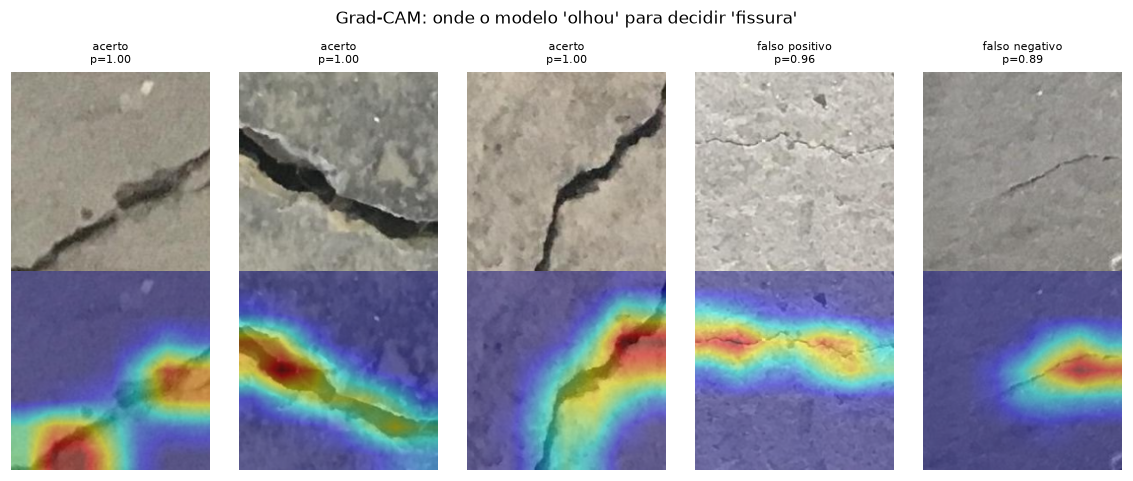

In [15]:
det = CrackDetector(SELECTED, MODELS, device=DEVICE)
sel = list(idx_tp[:3]) + list(idx_fp[:3]) + list(idx_fn[:2])
labels = ["acerto"] * 3 + ["falso positivo"] * min(3, len(idx_fp)) + ["falso negativo"] * min(2, len(idx_fn))
fig, ax = plt.subplots(2, len(sel), figsize=(2.1 * len(sel), 4.4))
for j, (i, lab) in enumerate(zip(sel, labels)):
    img = X["test"][i]; cam = det.gradcam(img)
    ax[0, j].imshow(img); ax[0, j].set_title(f"{lab}\np={p_test[i]:.2f}", fontsize=7)
    ax[1, j].imshow(overlay_cam(img, cam)); ax[0, j].axis("off"); ax[1, j].axis("off")
plt.suptitle("Grad-CAM: onde o modelo 'olhou' para decidir 'fissura'"); plt.tight_layout(); savefig("11_gradcam"); plt.show()

In [16]:
# Que condições visuais concentram os erros? (brilho, contraste, nitidez, textura)
def cond(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return {"brilho": g.mean(), "contraste": g.std(), "nitidez (var. Laplaciano)": cv2.Laplacian(g, cv2.CV_64F).var()}
C = pd.DataFrame([cond(x) for x in X["test"]]); C["grupo"] = np.select([pred & (y_test == 0), ~pred & (y_test == 1), y_test == 1], ["FP", "FN", "TP"], "TN")
display(C.groupby("grupo").median().round(1))
RESULTS["erros_condicoes"] = C.groupby("grupo").median().round(1).to_dict()

,brilho,contraste,nitidez (var. Laplaciano)
grupo,,,
FN,143.3,9.0,32.2
FP,188.3,14.2,124.5
TN,190.0,7.1,11.1
TP,163.7,30.6,47.3


### Robustez a interferências de campo
Aplicamos ao conjunto de teste perturbações que imitam o que uma câmera na rua enfrenta — **sombra** de poste/marquise,
**pouca luz**, **superexposição**, **desfoque**, **borrão de movimento**, **ruído**, **compressão JPEG**, **obstáculo** cobrindo
parte da superfície e **baixa resolução** — e medimos a queda de recall/precisão no limiar de triagem de cada modelo.
Comparamos os 4 modelos; o contraste mais importante é **ResNet18 × ResNet18 + campo** (mesma arquitetura, só muda o aumento de dados).
As perturbações daqui (`perturb.py`, sementes fixas, sobre o TESTE) são implementações diferentes das usadas no treino (`model.field_augment`),
mas da mesma família de condições — o ganho mostra robustez a condições *simuladas*; a validação final precisa de fotos reais de campo.

F1 no TESTE por condição (limiar de triagem de cada modelo):


modelo,mobilenet_v3_large,resnet18,resnet18_campo,resnet50
condição,,,,
original,0.9989,0.9977,0.9989,0.9966
sombra,0.8227,0.8346,0.9977,0.7559
escura,0.1159,0.2298,0.9971,0.6916
superexposta,0.7822,0.8991,0.9937,0.9658
desfoque,0.9885,0.9977,0.9510,0.9966
borrão de movimento,0.9498,0.9920,0.8642,0.9920
ruído,0.0000,0.8530,0.9994,0.9773
JPEG forte,0.9943,0.9977,0.9977,0.9891
obstáculo,0.7615,0.6911,0.9566,0.6957


Detalhe do modelo selecionado (resnet18_campo):


,precisao,recall,f1,especificidade,fp,fn
condição,,,,,,
original,0.9989,0.9989,0.9989,0.9988,1,1
sombra,0.9989,0.9966,0.9977,0.9988,1,3
escura,0.9989,0.9954,0.9971,0.9988,1,4
superexposta,1.0000,0.9875,0.9937,1.0000,0,11
desfoque,1.0000,0.9066,0.9510,1.0000,0,82
borrão de movimento,1.0000,0.7608,0.8642,1.0000,0,210
ruído,1.0000,0.9989,0.9994,1.0000,0,1
JPEG forte,1.0000,0.9954,0.9977,1.0000,0,4
obstáculo,0.9348,0.9795,0.9566,0.9278,60,18


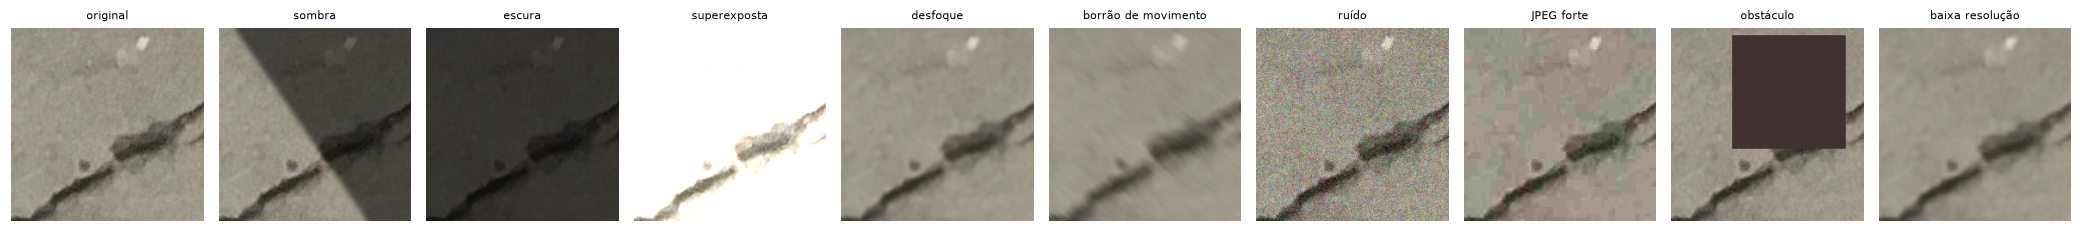

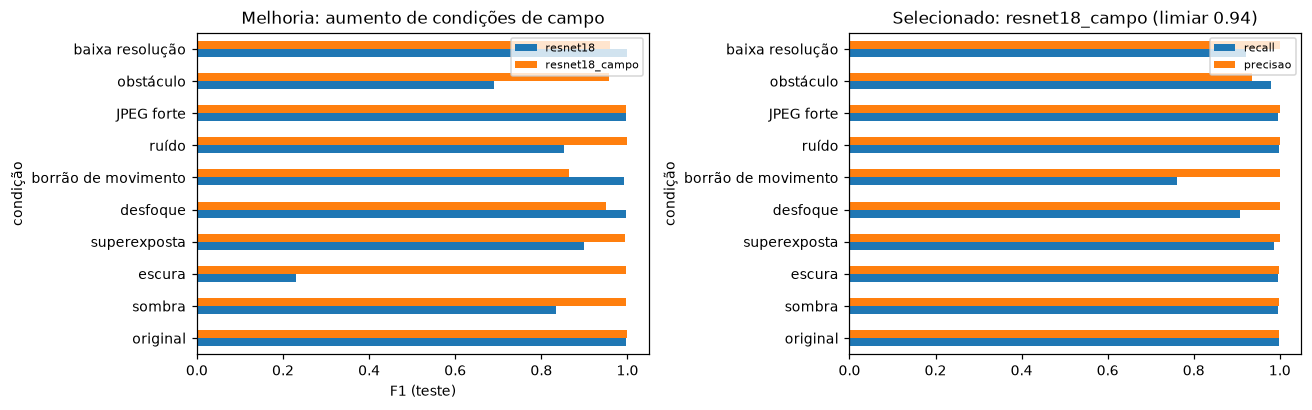

In [17]:
rob_all = []
examples = {}
for cond in perturb.PERTURBATIONS:
    Xp = perturb.apply_all(X["test"], cond, seed=SEED)
    examples[cond] = Xp[idx_tp[0]]
    for a in models:
        pp = M.probs_from_logits(M.predict_logits(models[a], Xp, DEVICE), calib[a]["T"])
        r = M.classification_report(y_test, pp, thr[a]["triagem"]); r.update(condição=cond, modelo=a); rob_all.append(r)
    del Xp
rob_all = pd.DataFrame(rob_all)
rob_all[["modelo", "condição", "precisao", "recall", "f1", "fp", "fn"]].to_csv(ROOT / "reports" / "robustez.csv", index=False)
f1_tab = rob_all.pivot(index="condição", columns="modelo", values="f1").loc[list(perturb.PERTURBATIONS)]
f1_tab.loc["média (perturbadas)"] = f1_tab.drop("original").mean()
print("F1 no TESTE por condição (limiar de triagem de cada modelo):"); display(f1_tab.round(4))
rob = rob_all[rob_all.modelo == SELECTED].set_index("condição")[["precisao", "recall", "f1", "especificidade", "fp", "fn"]]
print(f"Detalhe do modelo selecionado ({SELECTED}):"); display(rob.round(4))
RESULTS["robustez"] = rob.round(4).to_dict(orient="index")
RESULTS["robustez_f1_modelos"] = f1_tab.round(4).to_dict(orient="index")

fig, ax = plt.subplots(1, len(examples), figsize=(1.9 * len(examples), 2.4))
for a, (k, v) in zip(ax, examples.items()): a.imshow(v); a.set_title(k, fontsize=7); a.axis("off")
plt.tight_layout(); savefig("12_perturbacoes"); plt.show()
cmp_cols = [c for c in ["resnet18", "resnet18_campo"] if c in f1_tab.columns] or list(f1_tab.columns)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
f1_tab.drop("média (perturbadas)")[cmp_cols].plot.barh(ax=ax[0]); ax[0].set_xlabel("F1 (teste)"); ax[0].set_title("Melhoria: aumento de condições de campo"); ax[0].legend(fontsize=7)
rob[["recall", "precisao"]].plot.barh(ax=ax[1]); ax[1].set_title(f"Selecionado: {SELECTED} (limiar {t_tri:.2f})"); ax[1].legend(fontsize=7)
plt.tight_layout(); savefig("13_robustez"); plt.show()

## 8. Localização em imagens maiores (fachada)
O modelo foi treinado em recortes; numa foto inteira usamos **janelas deslizantes** (sobreposição de 25%), juntamos as
janelas acima do limiar em regiões e desenhamos caixas com a confiança máxima. Para avaliar, montamos uma "fachada" de
6×16 recortes **de teste** com trechos fissurados contínuos, sabendo onde está cada fissura.

janelas: 96 | latência total 2584 ms | precisão 1.000 recall 1.000


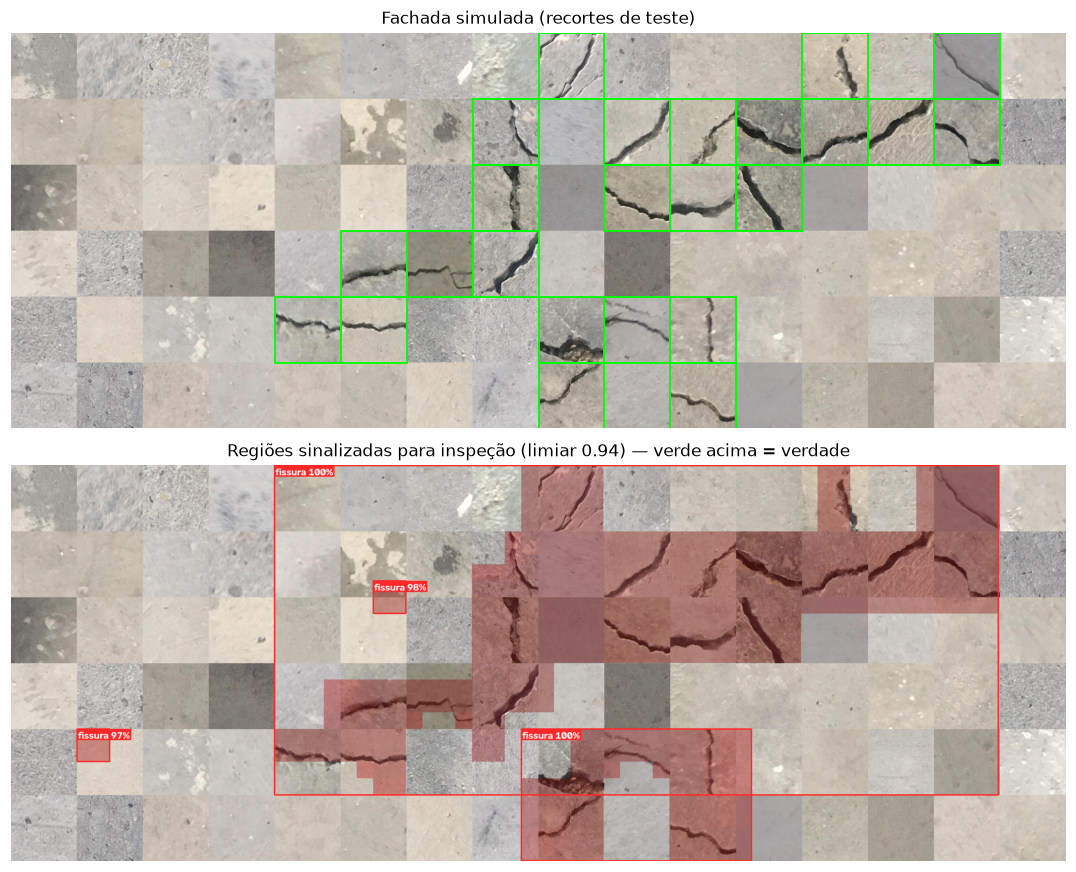

In [18]:
test_df = df[df.split == "test"]
mosaic, truth = video.build_mosaic(test_df[test_df.label == 1].path.tolist(), test_df[test_df.label == 0].path.tolist(), rows=6, cols=16, seed=SEED)
res = det.analyze(mosaic, tile=227, overlap=0.0)       # sem sobreposição -> 1 janela = 1 recorte (avaliação)
grid_pred = np.array([t.prob for t in res.tiles]).reshape(truth.shape) >= t_tri
tile_rep = M.classification_report(truth.ravel(), np.array([t.prob for t in res.tiles]), t_tri)
print(f"janelas: {res.n_tiles} | latência total {res.latency_ms:.0f} ms | precisão {tile_rep['precisao']:.3f} recall {tile_rep['recall']:.3f}")
res_vis = det.analyze(mosaic, tile=227, overlap=0.25)
vis = draw_analysis(mosaic, res_vis, t_tri)
fig, ax = plt.subplots(2, 1, figsize=(14, 8))
ax[0].imshow(mosaic); ax[0].set_title("Fachada simulada (recortes de teste)"); ax[0].axis("off")
for r, c in zip(*np.where(truth)): ax[0].add_patch(plt.Rectangle((c * 227, r * 227), 227, 227, fill=False, ec="lime", lw=1.2))
ax[1].imshow(vis); ax[1].set_title(f"Regiões sinalizadas para inspeção (limiar {t_tri:.2f}) — verde acima = verdade"); ax[1].axis("off")
plt.tight_layout(); savefig("14_fachada"); plt.show()
cv2.imwrite(str(DEMO / "fachada_teste.jpg"), mosaic[..., ::-1]); cv2.imwrite(str(DEMO / "fachada_resultado.jpg"), vis[..., ::-1])
RESULTS["fachada"] = {k: tile_rep[k] for k in ["precisao", "recall", "f1"]} | {"janelas": res.n_tiles, "latencia_ms": res.latency_ms}

## 9. Monitoramento contínuo (vídeo)
Simulamos uma câmera percorrendo uma fachada maior (8×22 recortes de teste) em zigue-zague, com **variação de luz**, **sombra de poste
passando** e **tremor**. Cada quadro 1024×576 é dividido em janelas 227 px; o alerta usa média móvel + histerese
(liga após 3 quadros acima do limiar; desliga abaixo de 0,8×limiar) para não piscar com um quadro ruim.

{
 "quadros": 360,
 "resolucao": "1024x576",
 "janelas_por_quadro": 24,
 "lat_modelo_media_ms": 76.70137805552157,
 "lat_modelo_p95_ms": 121.18993000294724,
 "fps_pipeline_completo": 6.606163154954714,
 "quadros_em_alerta": 314
}


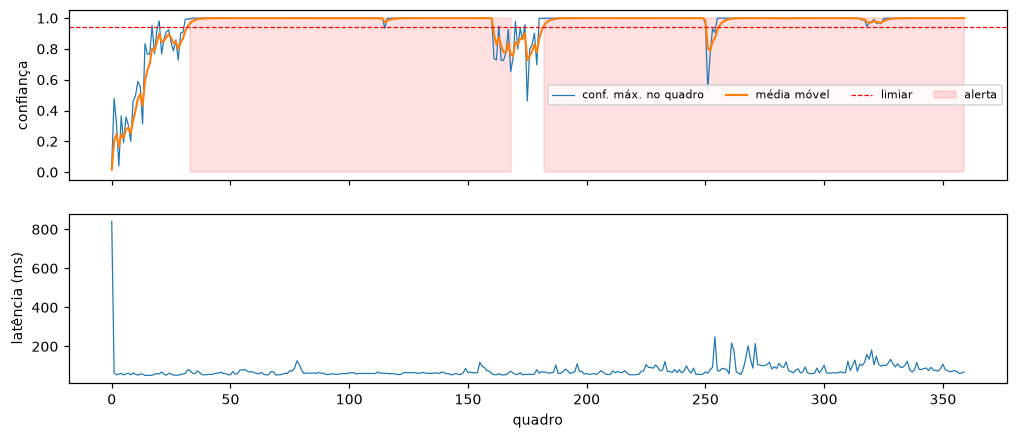

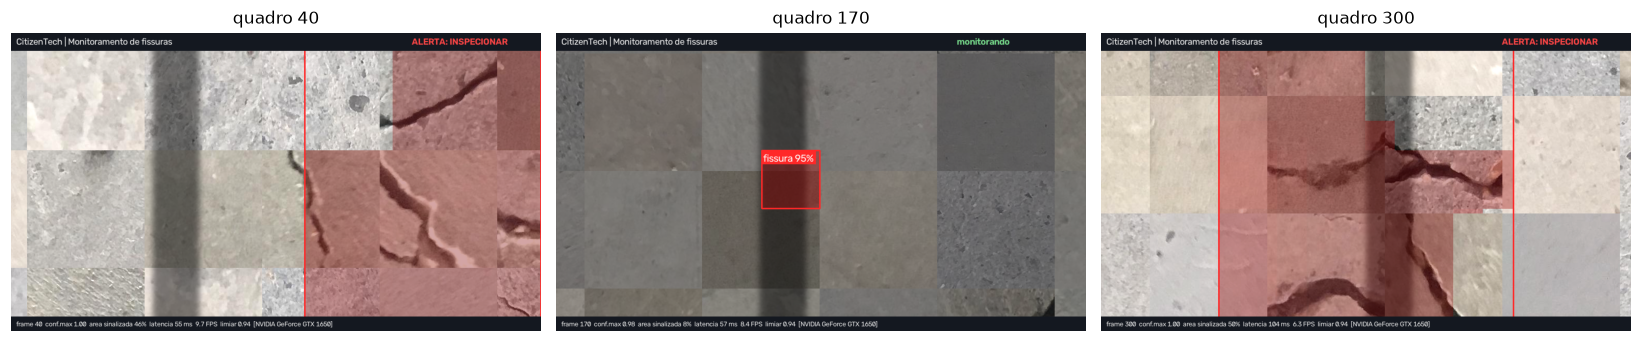

In [19]:
mosaic_v, truth_v = video.build_mosaic(test_df[test_df.label == 1].path.tolist(), test_df[test_df.label == 0].path.tolist(), rows=8, cols=22, seed=7)
frames_in = list(video.pan_frames(mosaic_v, 1024, 576, n_frames=360))
video.write_video(frames_in, DEMO / "entrada_camera.mp4", fps=24)
out_frames, recs = [], []
t0 = time.perf_counter()
for f, r in video.monitor(det, frames_in, threshold=t_tri, tile=227):
    out_frames.append(f); recs.append(r)
wall = time.perf_counter() - t0
video.write_video(out_frames, DEMO / "monitoramento_fissuras.mp4", fps=24)
R = pd.DataFrame([r.__dict__ for r in recs]); R.to_csv(ROOT / "reports" / "monitoramento_quadros.csv", index=False)
vid_stats = {"quadros": len(R), "resolucao": "1024x576", "janelas_por_quadro": det.analyze(frames_in[0], tile=227).n_tiles,
             "lat_modelo_media_ms": R.latency_ms.mean(), "lat_modelo_p95_ms": R.latency_ms.quantile(.95),
             "fps_pipeline_completo": len(R) / wall, "quadros_em_alerta": int(R.alerta.sum())}
print(json.dumps(vid_stats, indent=1)); RESULTS["video"] = vid_stats

fig, ax = plt.subplots(2, 1, figsize=(11, 4.4), sharex=True)
ax[0].plot(R.frame, R.prob_max, lw=.8, label="conf. máx. no quadro"); ax[0].plot(R.frame, R.score_ema, lw=1.4, label="média móvel")
ax[0].axhline(t_tri, color="r", ls="--", lw=.8, label="limiar"); ax[0].fill_between(R.frame, 0, 1, where=R.alerta, color="r", alpha=.12, label="alerta")
ax[0].legend(fontsize=7, ncol=4); ax[0].set_ylabel("confiança")
ax[1].plot(R.frame, R.latency_ms, lw=.8); ax[1].set_ylabel("latência (ms)"); ax[1].set_xlabel("quadro")
savefig("15_monitoramento"); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(15, 3))
for a, k in zip(ax, [40, 170, 300]): a.imshow(out_frames[k]); a.axis("off"); a.set_title(f"quadro {k}")
plt.tight_layout(); savefig("16_quadros_video"); plt.show()

## 10. Desempenho: latência e FPS
Medimos a latência **só do modelo** (tensor pronto, `cuda.synchronize`, 15 aquecimentos + 100 medições) em GPU fp32/fp16 e CPU,
para lote 1 (uma foto enviada pelo cidadão) e lote 32 (janelas de um quadro de vídeo), e a **troca qualidade × velocidade** ao reduzir a resolução de entrada.

In [20]:
B = []
uniq = {}
for n_, cfg_ in CONFIGS.items():   # mesma arquitetura = mesma latência -> mede uma vez
    uniq.setdefault(cfg_["arch"], models[n_])
for arch, m in uniq.items():
    for dev, half in ([("cuda", False), ("cuda", True)] if DEVICE == "cuda" else []) + [("cpu", False)]:
        for bs in [1, 32]:
            mm = M.build_model(arch, pretrained=False); mm.load_state_dict(m.state_dict())
            r = bench.bench_model(arch, dev, batch=bs, half=half, model=mm, n_iter=100 if dev == "cuda" else (30 if bs == 1 else 5), warmup=15 if dev == "cuda" else 3)
            r["params_M"] = round(M.count_params(m), 2); B.append(r)
    torch.cuda.empty_cache()
B = pd.DataFrame(B); display(B.round(2)); B.to_csv(ROOT / "reports" / "benchmark.csv", index=False)
RESULTS["benchmark"] = B.round(3).to_dict(orient="records")

,arquitetura,dispositivo,precisao,resolucao,lote,lat_lote_ms,lat_p95_ms,lat_img_ms,imgs_por_s,saida_valida,params_M
0,mobilenet_v3_large,cuda,fp32,224,1,20.66,35.96,20.66,48.40,True,4.20
1,mobilenet_v3_large,cuda,fp32,224,32,36.75,41.37,1.15,870.69,True,4.20
2,mobilenet_v3_large,cuda,fp16,224,1,26.75,43.00,26.75,37.38,True,4.20
3,mobilenet_v3_large,cuda,fp16,224,32,42.67,46.22,1.33,749.94,True,4.20
4,mobilenet_v3_large,cpu,fp32,224,1,52.87,83.79,52.87,18.91,True,4.20
5,mobilenet_v3_large,cpu,fp32,224,32,686.87,722.11,21.46,46.59,True,4.20
6,resnet18,cuda,fp32,224,1,6.12,9.68,6.12,163.43,True,11.18
7,resnet18,cuda,fp32,224,32,49.47,52.95,1.55,646.86,True,11.18
8,resnet18,cuda,fp16,224,1,12.49,17.91,12.49,80.10,True,11.18
9,resnet18,cuda,fp16,224,32,227.12,230.86,7.10,140.90,True,11.18


,resolucao,f1,recall,precisao,lat_img_ms,fps_lote1
0,224,0.9989,0.9989,0.9989,7.1893,139.0960
1,192,0.9977,0.9989,0.9966,6.4044,156.1428
2,160,0.9983,0.9989,0.9977,7.7507,129.0198
3,128,0.9977,0.9989,0.9966,8.6902,115.0718
4,96,0.9977,0.9989,0.9966,6.4473,155.1042


ponta a ponta, 1 imagem: {'lat_media_ms': np.float64(8.72), 'lat_p95_ms': np.float64(14.18), 'fps': np.float64(114.74)}


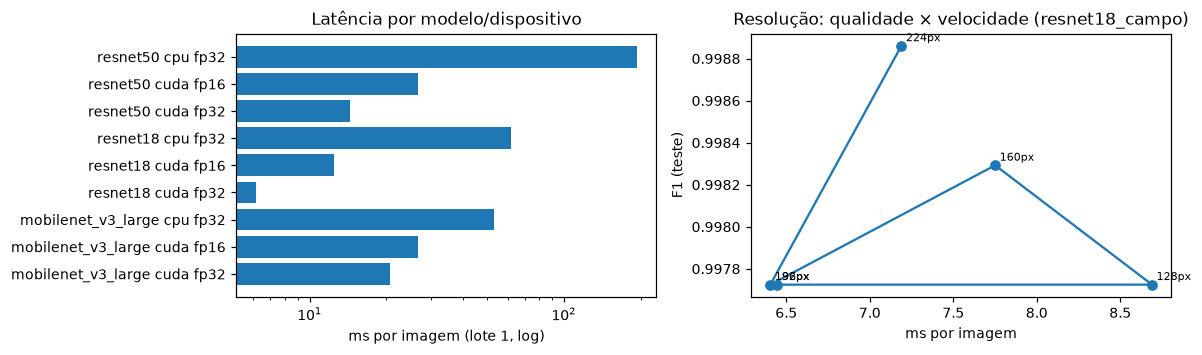

In [21]:
# Qualidade x velocidade variando a resolução de entrada do modelo selecionado
RS = []
for res_ in [224, 192, 160, 128, 96]:
    Xr = np.stack([cv2.resize(x, (res_, res_), interpolation=cv2.INTER_AREA) for x in X["test"]])
    pr = M.probs_from_logits(M.predict_logits(models[SELECTED], Xr, DEVICE), T)
    rep = M.classification_report(y_test, pr, t_tri)
    lat = bench.bench_model(SELECTED, DEVICE, res=res_, batch=1, half=False, model=models[SELECTED], n_iter=100)
    RS.append({"resolucao": res_, "f1": rep["f1"], "recall": rep["recall"], "precisao": rep["precisao"], "lat_img_ms": lat["lat_img_ms"], "fps_lote1": lat["imgs_por_s"]})
RS = pd.DataFrame(RS); display(RS.round(4)); RS.to_csv(ROOT / "reports" / "resolucao.csv", index=False); RESULTS["resolucao"] = RS.round(4).to_dict(orient="records")

# Ponta a ponta de uma foto (leitura -> pré-processamento -> modelo -> probabilidade), como no app
img0 = X["test"][0].copy()
ts = []
for i in range(60):
    t0 = time.perf_counter(); det.predict_crops([img0]); torch.cuda.synchronize() if DEVICE == "cuda" else None; ts.append(time.perf_counter() - t0)
e2e = {"lat_media_ms": 1000 * np.mean(ts[10:]), "lat_p95_ms": 1000 * np.percentile(ts[10:], 95), "fps": 1 / np.mean(ts[10:])}
print("ponta a ponta, 1 imagem:", {k: round(v, 2) for k, v in e2e.items()}); RESULTS["ponta_a_ponta_1img"] = e2e

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
g = B[(B.lote == 1)]; lab = g.arquitetura + " " + g.dispositivo + " " + g.precisao
ax[0].barh(lab, g.lat_img_ms); ax[0].set_xscale("log"); ax[0].set_xlabel("ms por imagem (lote 1, log)"); ax[0].set_title("Latência por modelo/dispositivo")
ax[1].plot(RS.lat_img_ms, RS.f1, "o-")
for _, r in RS.iterrows(): ax[1].annotate(f"{int(r.resolucao)}px", (r.lat_img_ms, r.f1), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].set_xlabel("ms por imagem"); ax[1].set_ylabel("F1 (teste)"); ax[1].set_title(f"Resolução: qualidade × velocidade ({SELECTED})")
plt.tight_layout(); savefig("17_desempenho"); plt.show()

## 11. Resumo salvo para o relatório e o app

In [22]:
final = met[(met.conjunto == "test")].set_index(["modelo", "criterio"])
RESULTS["teste"] = {f"{a}|{c}": final.loc[(a, c)][["limiar", "acuracia", "precisao", "recall", "f1", "especificidade", "roc_auc", "pr_auc", "fp", "fn", "tp", "tn"]].astype(float).round(4).to_dict()
                    for a, c in final.index}
RESULTS["validacao"] = {f"{a}|{c}": r[["limiar", "precisao", "recall", "f1"]].astype(float).round(4).to_dict()
                        for (a, c), r in met[met.conjunto == "val"].set_index(["modelo", "criterio"]).iterrows()}
RESULTS["calibracao"] = calib; RESULTS["limiares"] = thr
RESULTS["treino"] = {a: {"min": round(train_time[a] / 60, 2), "historico": hist[a]} for a in models}
(ROOT / "reports" / "metrics.json").write_text(json.dumps(RESULTS, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
sel = RESULTS["teste"][f"{SELECTED}|triagem"]
print(f"Modelo: {SELECTED} | limiar triagem {sel['limiar']:.3f} | precisão {sel['precisao']:.4f} | recall {sel['recall']:.4f} | F1 {sel['f1']:.4f}")

Modelo: resnet18_campo | limiar triagem 0.945 | precisão 0.9989 | recall 0.9989 | F1 0.9989
